# Simulation analysis: α sweep and γ swap from established diverse states

All runs use the percolation lattice (200 × 200, largest cluster only), with directed interaction cycles
of length 2-6 rejected (`max_forbidden_cycle_length = 6`). Only stored results are read here: the
`analysis.npz` records, `batch_plan.json`, and checkpoints. Nothing is simulated.

| Experiment | Batch | Runs | Start | Time span |
|---|---|---|---|---|
| **α sweep** (p = 0.2, γ = 0.03) | Branch r1: `no_short_cycles_alpha_p20_g003_20261021_011454_0f93dba1` | 12 (α = 0.001 … 0.012) | parent A at t = 50M | 50M → 150M |
| | Branch r2: `no_short_cycles_alpha_p20_g003_rep2_20261022_005553_dfacd28f` | 12 (same α) | the same parent A state, new seeds | 50M → 150M |
| | Fresh r3-r5: `alpha_p20_g003_fresh_rep3-5_analysis` | 36 (3 per α) | one species, a new lattice per run | 0 → 100M |
| **γ swap** (p = 0.3, α = 0.0125) | `no_short_cycles_gamma_p30_from_g003_20261022_005553_5940261e` | 12 (γ = 0.02 … 0.15) | parent B at t = 50M | 50M → 150M |

Parents A and B are runs of the p × γ grid (`no_short_cycles_p_gamma_20261009_011738_ef440b70`). Both
start from one species with α = 0.0125 and γ = 0.03; A uses p = 0.2 and B uses p = 0.3.

**How the runs relate.**
- A branch keeps its parent's lattice, community and interaction matrix Γ, draws fresh random numbers
  from its own seed, and changes one parameter. A changed γ applies only to species introduced after the
  branch.
- Branch r1 and r2 start from the **same** state with different seeds. They are two independent
  continuations of one community, not independent replicates of the α experiment.
- The fresh runs are independent of each other and of the branches.
- The γ swap includes γ = 0.03, which keeps all of parent B's parameters and is its control. The α sweep
  has no such control (α = 0.0125 was not branched), so parent A's own history is its only reference.
- New species arrive at α·γ per time unit, so changing α *or* γ also changes the arrival rate:
  3.75 × 10⁻⁴ per step in both parents, 3 × 10⁻⁵ … 3.6 × 10⁻⁴ across the α sweep, and
  2.5 × 10⁻⁴ … 1.9 × 10⁻³ across the γ swap.

The setup cell checks every branch against its parent's stored state. The community tables (sections 9
and 12) compare the species introduced in each branch with α·γ·T.

**Time.** The analysis records store absolute time t. One time unit ("step") is N = 40,000 microscopic
invasion attempts, blocked sites included. A branch's record starts at the branch point, so it does not
repeat the parent's history.
- Comparisons use **run time** t − t₀, where t₀ is the branch point (50M) for branches and 0 for fresh
  runs. The parent's last 20M steps appear at negative run time, so the change point sits at 0.
- The lineage chart (section 1) and the swap zoom (section 13) use **absolute** t.

**Regimes and averages.**
- A run is in the *high* regime from the moment its smoothed living species reach `HIGH` = 50 until they
  fall to `LOW` = 10. Its starting regime is read from its first, unsmoothed sample. This is the
  two-threshold rule of `MS.detect_diversity_swaps`, but with fixed thresholds, so runs that never become
  diverse can still be compared.
- Smoothing is a Gaussian with σ = 20 samples (0.2M steps). It is used for the drawn lines and for
  regime detection.
- Means and the `<10` / `10-50` / `>50` shares come from the raw samples of each run's second half (run
  time 50-100M). The high-regime share uses the smoothed regimes over the same window. Parents are
  averaged over 25-50M.

In [1]:
# Load every run from its analysis record, check how each branched batch relates to its
# parent run, and give each run one colour and marker for the whole notebook.
import json
import os
import sys
from importlib import reload
from pathlib import Path, PureWindowsPath
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm, PowerNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# The notebooks live in analysis/; work from the project root, so sim_modules and the
# relative checkpoints/ paths resolve.
if Path.cwd().name == "analysis":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import sim_modules as MS

reload(MS)

CHECKPOINTS = Path(r"D:\Luc\ActualMasterProject\MasterProject\checkpoints")
GRID_ROOT = CHECKPOINTS / "no_short_cycles_p_gamma_20261009_011738_ef440b70"
# One entry per batch folder; "repeat" is the number of the batch's first repeat. Add a line
# here (and a style below) to include another batch in every plot.
BATCHES = [
    {"experiment": "alpha", "group": "branch", "repeat": 1,
     "folder": CHECKPOINTS / "no_short_cycles_alpha_p20_g003_20261021_011454_0f93dba1"},
    {"experiment": "alpha", "group": "branch", "repeat": 2,
     "folder": CHECKPOINTS / "no_short_cycles_alpha_p20_g003_rep2_20261022_005553_dfacd28f"},
    {"experiment": "alpha", "group": "fresh", "repeat": 3,
     "folder": CHECKPOINTS / "alpha_p20_g003_fresh_rep3-5_analysis"},
    {"experiment": "gamma", "group": "branch", "repeat": 1,
     "folder": CHECKPOINTS / "no_short_cycles_gamma_p30_from_g003_20261022_005553_5940261e"},
]
# Colour and marker of each run, by (experiment, repeat). One panel never shows more than
# branch r1-r2 or fresh r3-r5 together; the summaries show all five, with the marker as a
# second cue. Pairs checked for colour-vision deficiency with the dataviz palette validator;
# the closest pair (red/green, r3/r5) also gets the most different markers.
RUN_STYLES = {
    ("alpha", 1): ("#2a78d6", "o"),  # Branch r1: blue circle
    ("alpha", 2): ("#1baf7a", "s"),  # Branch r2: aqua square
    ("alpha", 3): ("#e34948", "^"),  # Fresh r3: red triangle
    ("alpha", 4): ("#eda100", "D"),  # Fresh r4: yellow diamond
    ("alpha", 5): ("#008300", "X"),  # Fresh r5: green cross
    ("gamma", 1): ("#6250d6", "o"),  # gamma swap: violet circle (one run per gamma)
}
PARENT_COLOR = "#52514e"  # Parent runs and reference lines.
BAND_COLOR = "#ecebe6"  # Between the two regime thresholds.
SURFACE = "#fcfcfb"
SYMBOL = {"alpha": "α", "gamma": "γ"}
# Reference lines keep one meaning each: parent mean dashed, end of run dotted, γ dash-dot.
PARENT_MEAN_LS, END_OF_RUN_LS, GAMMA_LS = "--", ":", "-."

AVERAGE_FROM_FRACTION = 0.5  # Means and shares use t >= t0 + this x run length.
SMOOTH_SIGMA = 20  # Gaussian width in tracked samples (0.2M steps), as in show_results.
LOW, HIGH = 10, 50  # Living-species thresholds of the low and high regimes.
PRE_BRANCH = 20  # Millions of steps of the parent shown before each branch.
MARK_EVERY = 1000  # Samples (10M steps) between the sparse identity markers on lines.
CONNECTANCE_MIN_SPECIES = 30  # Below this, links / (S(S-1)) rests on a handful of links.

RESULT_STYLE = {
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.facecolor": SURFACE,
    "axes.titlesize": 10, "axes.labelsize": 9, "axes.titlelocation": "left",
    "xtick.color": PARENT_COLOR, "ytick.color": PARENT_COLOR,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "legend.frameon": False, "legend.fontsize": 8, "figure.facecolor": "white",
}


def _plan(root):
    return json.loads((Path(root) / "batch_plan.json").read_text(encoding="utf-8"))


def _window_mean(times, values, from_timestep):
    """Trapezoidal time mean of the valid samples at or after from_timestep."""
    keep = (times >= from_timestep) & np.isfinite(values)
    times, values = times[keep].astype(np.float64), values[keep]
    if times.size < 2:
        return np.nan
    return float(np.sum(np.diff(times) * (values[:-1] + values[1:]) / 2.0)
                 / (times[-1] - times[0]))


def _regimes(smoothed, start_high):
    """True where a run is in the high regime: it switches up on reaching HIGH and
    down on falling to LOW, so lingering between the two is not a switch. The start
    regime comes from the raw first sample, because smoothing would blend a collapse
    right after a branch into the starting value."""
    high = np.empty(smoothed.size, dtype=bool)
    state = bool(start_high)
    for index, value in enumerate(smoothed):
        if state and value <= LOW:
            state = False
        elif not state and value >= HIGH:
            state = True
        high[index] = state
    return high


def _series(record, start, length):
    """Living species, patches and regime summaries of one record over start -> start + length."""
    times = np.asarray(record["tracked_timesteps"], dtype=np.int64)
    keep = (times >= start) & (times <= start + length)
    times = times[keep]
    diversity = np.asarray(record["diversity_history"], dtype=np.float64)[keep]
    patches = np.asarray(record["patch_history"], dtype=np.float64)[keep]
    patches[patches < 0] = np.nan  # Lattice was never counted.
    smoothed = MS._gaussian_smooth(diversity, SMOOTH_SIGMA)
    high = _regimes(smoothed, diversity[0] >= 0.5 * (LOW + HIGH))
    switches = np.flatnonzero(high[1:] != high[:-1]) + 1
    half = start + AVERAGE_FROM_FRACTION * length
    late = times >= half
    return {
        "times": times, "elapsed": (times - start) / 1e6, "diversity": diversity,
        "smoothed": smoothed, "patches": patches, "high": high, "late": diversity[late],
        "share_high": float(np.mean(high[late])),
        "mean": _window_mean(times, diversity, half),
        "mean_patches": _window_mean(times, patches, half),
        "switch_elapsed": (times[switches] - start) / 1e6, "switch_up": high[switches],
        "final": int(diversity[-1]), "finished": int(times[-1]) >= start + length,
    }


def _group_title(run):
    """Panel title of a run's group: its parent and branch point, or a fresh start."""
    if run["parent"] is None:
        return "Fresh start from one species (t₀ = 0)"
    parent = parents[run["parent"]]
    return (f"Branched from parent {parent['letter']} at t₀ = {parent['branch'] / 1e6:g}M "
            f"({SYMBOL[run['experiment']]} changed at t₀)")


def _run_name(experiment, group, repeat):
    if experiment == "gamma":
        return "γ swap"
    return f"{'Branch' if group == 'branch' else 'Fresh'} r{repeat}"


all_runs, parents, lineage = [], {}, []
for batch in BATCHES:
    plan = _plan(batch["folder"])
    initial = plan.get("initial_state") or {}
    start = int(initial.get("timestep", 0))
    source = initial.get("source_directory")
    if source is not None and source not in parents:
        record = MS.load_analysis(source)
        state = MS.load_checkpoint(Path(source) / f"checkpoint_{start:012d}.npz")
        parent = _series(record, 0, start)  # Parents ran 0 -> branch point.
        letter = chr(ord("A") + len(parents))
        parent.update(
            letter=letter, name=f"Parent {letter}: grid run p = {record['p']:g}, "
                                f"γ = {record['gamma']:g}, α = {record['alpha']:g}",
            folder=Path(source), branch=start, p=record["p"], gamma=record["gamma"],
            alpha=record["alpha"], at_branch=int(state["diversity"]),
            usable_sites=int(record["usable_sites"]),
            fingerprint_ok=MS._branch_state_fingerprint(state) == initial["state_fingerprint"],
        )
        parents[source] = parent
    for job in plan["jobs"]:
        config = job["config"]
        job_dir = Path(batch["folder"]) / PureWindowsPath(job["checkpoint_dir"]).name
        record = MS.load_analysis(job_dir) if job_dir.is_dir() else None
        if record is None:
            print(f"{batch['folder'].name}: no analysis record in {job_dir.name}, skipped")
            continue
        repeat = batch["repeat"] + int(job["repeat_index"])
        color, marker = RUN_STYLES[(batch["experiment"], repeat)]
        run = _series(record, start, int(config["T"]))
        events = np.asarray(record["event_timesteps"], dtype=np.int64)
        run.update(
            experiment=batch["experiment"], group=batch["group"], repeat=repeat,
            name=_run_name(batch["experiment"], batch["group"], repeat),
            color=color, marker=marker, batch=batch["folder"].name, checkpoint_dir=job_dir,
            value=float(config[batch["experiment"]]), alpha=float(config["alpha"]),
            gamma=float(config["gamma"]), p=float(config["p"]), seed=int(job["seed"]),
            start=start, length=int(config["T"]), parent=source,
            events=events[events >= start],  # The simulator's own swap detections.
            usable_sites=int(record["usable_sites"]),
            first_time=int(record["tracked_timesteps"][0]),
            first_sample=int(record["diversity_history"][0]),
            has_checkpoints=any(job_dir.glob("checkpoint_*.npz")),
        )
        all_runs.append(run)
    lineage.append({**batch, "plan": plan, "start": start, "source": source})

# Every run exactly once: distinct seeds and job folders.
assert len({run["seed"] for run in all_runs}) == len(all_runs), "a seed appears twice"
assert len({run["checkpoint_dir"] for run in all_runs}) == len(all_runs), "a folder appears twice"

for item in lineage:
    runs = [run for run in all_runs if run["batch"] == item["folder"].name]
    values = sorted({run["value"] for run in runs})
    names = sorted({run["name"] for run in runs})
    sym = SYMBOL[item["experiment"]]
    print(f"{', '.join(names)}  [{item['folder'].name}]\n"
          f"  {len(runs)} runs, {sum(run['finished'] for run in runs)} finished; {sym} = "
          f"{', '.join(f'{value:g}' for value in values)}; base seed {item['plan']['base_seed']}\n"
          f"  t = {item['start'] / 1e6:g}M -> {(item['start'] + runs[0]['length']) / 1e6:g}M; "
          f"p = {runs[0]['p']:g}, " + (f"γ = {runs[0]['gamma']:g}" if item["experiment"] == "alpha"
                                       else f"α = {runs[0]['alpha']:g}"))
    if item["source"] is None:
        sites = [run["usable_sites"] for run in runs]
        print(f"  from one species; own lattice per run ({min(sites)}-{max(sites)} usable sites)")
        continue
    parent = parents[item["source"]]
    same_lattice = all(run["usable_sites"] == parent["usable_sites"] for run in runs)
    starts_at_parent = all(run["first_sample"] == parent["at_branch"]
                           and run["first_time"] == parent["branch"] for run in runs)
    print(f"  branched from {parent['name']} at t = {parent['branch'] / 1e6:g}M "
          f"({parent['at_branch']} species; 25-50M mean {parent['mean']:.1f}, "
          f"{parent['share_high']:.0%} in the high regime)\n"
          f"  checks: state fingerprint {'matches' if parent['fingerprint_ok'] else 'DIFFERS'}; "
          f"lattice {'identical' if same_lattice else 'DIFFERS'} ({parent['usable_sites']} usable "
          f"sites); first sample {'is' if starts_at_parent else 'is NOT'} the parent's state at "
          f"t = {parent['branch'] / 1e6:g}M ({parent['at_branch']} species)")

# Fresh p = 0.3 grid runs (own lattices, 0 -> 50M) as a reference for the gamma swap.
gamma_parent = next(parents[run["parent"]] for run in all_runs if run["experiment"] == "gamma")
grid_refs = []
for job in _plan(GRID_ROOT)["jobs"]:
    job_dir = GRID_ROOT / PureWindowsPath(job["checkpoint_dir"]).name
    config = job["config"]
    if (np.isclose(config["p"], gamma_parent["p"]) and np.isclose(config["alpha"], gamma_parent["alpha"])
            and job_dir.resolve() != gamma_parent["folder"].resolve()):
        reference = _series(MS.load_analysis(job_dir), 0, int(config["T"]))
        reference.update(value=float(config["gamma"]), length=int(config["T"]),
                         p=float(config["p"]))
        grid_refs.append(reference)
print(f"γ-swap reference: grid runs from one species at p = {gamma_parent['p']:g} (0 -> 50M, "
      "own lattices), 25-50M mean: " + ", ".join(f"γ = {ref['value']:g}: {ref['mean']:.1f}"
                                                for ref in grid_refs))
print(f"Regimes: high from reaching {HIGH} until falling to {LOW} living species "
      f"(smoothed, σ = {SMOOTH_SIGMA} samples).")

Branch r1  [no_short_cycles_alpha_p20_g003_20261021_011454_0f93dba1]
  12 runs, 12 finished; α = 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01, 0.011, 0.012; base seed 6768
  t = 50M -> 150M; p = 0.2, γ = 0.03
  branched from Parent A: grid run p = 0.2, γ = 0.03, α = 0.0125 at t = 50M (129 species; 25-50M mean 94.5, 78% in the high regime)
  checks: state fingerprint matches; lattice identical (31834 usable sites); first sample is the parent's state at t = 50M (129 species)
Branch r2  [no_short_cycles_alpha_p20_g003_rep2_20261022_005553_dfacd28f]
  12 runs, 12 finished; α = 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01, 0.011, 0.012; base seed 6769
  t = 50M -> 150M; p = 0.2, γ = 0.03
  branched from Parent A: grid run p = 0.2, γ = 0.03, α = 0.0125 at t = 50M (129 species; 25-50M mean 94.5, 78% in the high regime)
  checks: state fingerprint matches; lattice identical (31834 usable sites); first sample is the parent's state at t = 50M (129 sp

## 1. Lineage and time coordinates

Each bar is a batch of runs on absolute time t. A fork marks a branch point, where batches start from a
parent's saved state with one parameter changed. Fresh runs and the grid reference runs have no parent.
The fresh runs cover 0 → 100M, so in every later plot they sit on the same run-time axis (t − t₀) as the
branches.

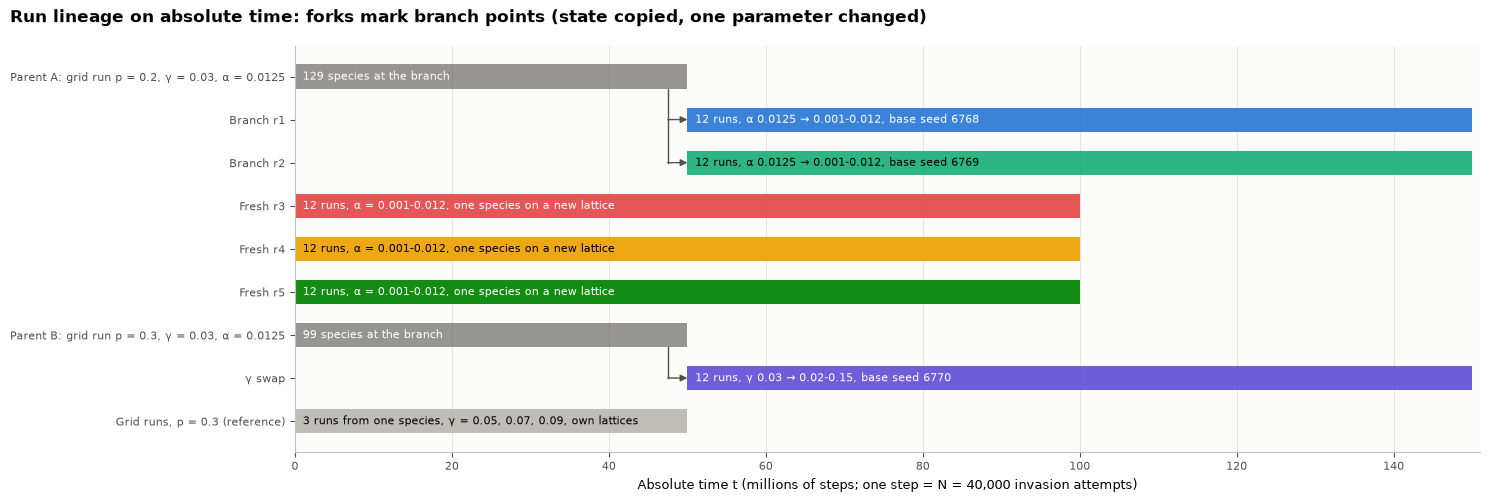

In [2]:
def plot_lineage():
    rows = []  # (label, start, end, colour, note, parent source or None)
    for item in lineage:
        runs = [run for run in all_runs if run["batch"] == item["folder"].name]
        if item["source"] is not None and not any(row[5] == ("parent", item["source"]) for row in rows):
            parent = parents[item["source"]]
            rows.append((parent["name"], 0, parent["branch"], PARENT_COLOR,
                         f"{parent['at_branch']} species at the branch", ("parent", item["source"])))
        sym = SYMBOL[item["experiment"]]
        values = sorted({run["value"] for run in runs})
        span = f"{sym} = {values[0]:g}-{values[-1]:g}"
        for repeat in sorted({run["repeat"] for run in runs}):
            members = [run for run in runs if run["repeat"] == repeat]
            first = members[0]
            if item["source"] is None:
                note = f"{len(members)} runs, {span}, one species on a new lattice"
            else:
                before = parents[item["source"]][item["experiment"]]
                note = (f"{len(members)} runs, {sym} {before:g} → {values[0]:g}-{values[-1]:g}, "
                        f"base seed {item['plan']['base_seed']}")
            rows.append((first["name"], first["start"], first["start"] + first["length"],
                         first["color"], note, ("branch", item["source"])))
    if grid_refs:
        rows.append((f"Grid runs, p = {grid_refs[0]['p']:g} (reference)", 0, grid_refs[0]["length"],
                     "#b9b8b1", f"{len(grid_refs)} runs from one species, γ = "
                     + ", ".join(f"{ref['value']:g}" for ref in grid_refs) + ", own lattices",
                     ("reference", None)))
    dark_text = {"#eda100", "#1baf7a", "#b9b8b1"}
    with plt.rc_context(RESULT_STYLE):
        fig, ax = plt.subplots(figsize=(15, 0.42 * len(rows) + 1.3))
        ax.set_axisbelow(True)
        for index, (label, start, end, color, note, _) in enumerate(rows):
            ax.barh(index, (end - start) / 1e6, left=start / 1e6, height=0.56, color=color,
                    alpha=0.6 if color == PARENT_COLOR else 0.92, lw=0)
            ax.text(start / 1e6 + 1, index, note, va="center", ha="left", fontsize=8,
                    color="black" if color in dark_text else "white")
        # A fork from each parent bar to its branches: a vertical spine, then one arrow per row.
        for parent_index, row in enumerate(rows):
            if row[5][0] != "parent":
                continue
            children = [index for index, other in enumerate(rows) if other[5] == ("branch", row[5][1])]
            x = row[2] / 1e6
            ax.plot([x - 2.5, x - 2.5], [parent_index + 0.28, max(children)], color=PARENT_COLOR, lw=1)
            for child in children:
                ax.annotate("", xy=(x, child), xytext=(x - 2.5, child),
                            arrowprops={"arrowstyle": "-|>", "color": PARENT_COLOR, "lw": 1,
                                        "shrinkA": 0, "shrinkB": 0})
        ax.set_yticks(range(len(rows)), [row[0] for row in rows], fontsize=8)
        ax.invert_yaxis()
        ax.set_xlim(0, max(row[2] for row in rows) / 1e6 + 1)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("Absolute time t (millions of steps; one step = N = 40,000 invasion attempts)")
        fig.suptitle("Run lineage on absolute time: forks mark branch points (state copied, one "
                     "parameter changed)", x=0.01, ha="left", fontsize=12, fontweight="bold")
        fig.tight_layout()
        plt.show()


plot_lineage()

## 2. α sweep: living species over time

Each α has two stacked panels: the two branches of parent A on top, the three fresh runs below. Every
run keeps its colour and marker throughout the notebook. Raw samples are drawn faintly under the
smoothed line, and the markers sit every 10M steps. Before 0, the top panel shows parent A's last 20M
steps (grey), and the vertical line marks where α changes. The dashed line is parent A's mean over 25-50M.
It is a reference, not a control: parent A was diverse only from about t ≈ 30M (78% of 25-50M in the
high regime), and no branch kept α = 0.0125. The grey band lies between the two regime thresholds.

The second figure shows single-species patches: connected groups of sites (four-neighbour, periodic
boundaries) held by one species. More patches mean a finer-grained, more mixed lattice.

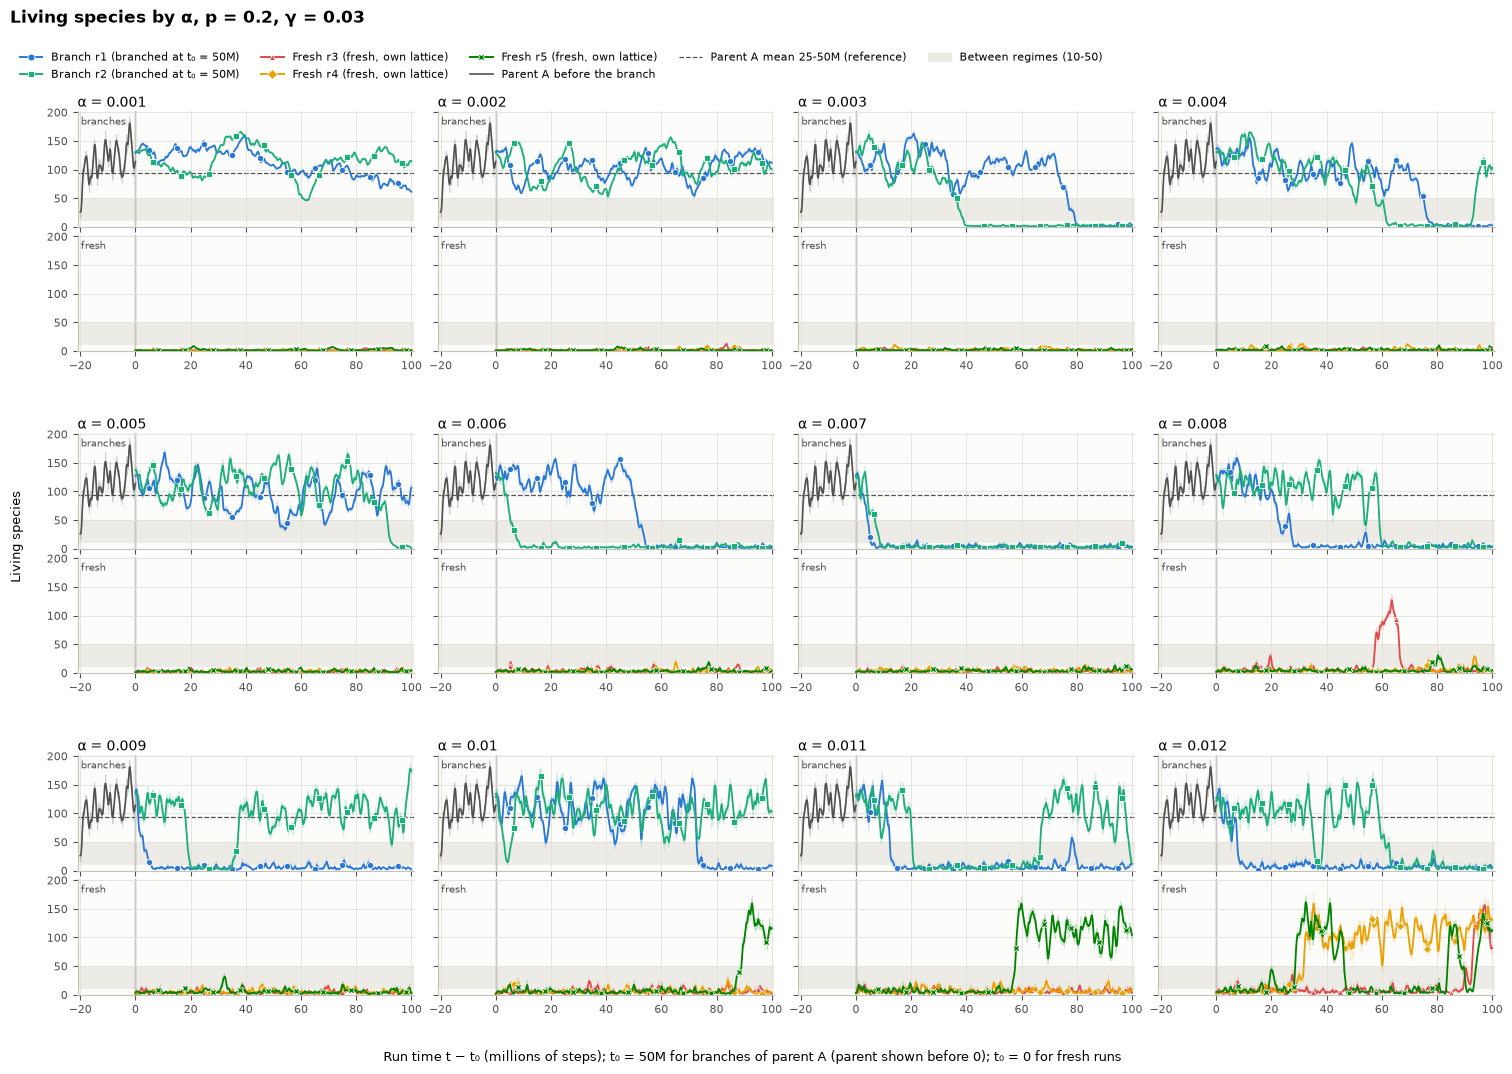

In [3]:
def _experiment_title(experiment):
    runs = [run for run in all_runs if run["experiment"] == experiment]
    fixed = ("γ", "gamma") if experiment == "alpha" else ("α", "alpha")
    return f"p = {runs[0]['p']:g}, {fixed[0]} = {runs[0][fixed[1]]:g}"


def _identity_handles(runs, detail=True):
    handles = []
    for repeat, name, color, marker, group in sorted(
            {(run["repeat"], run["name"], run["color"], run["marker"], run["group"]) for run in runs}):
        suffix = (" (branched at t₀ = 50M)" if group == "branch" else " (fresh, own lattice)")
        handles.append(Line2D([], [], color=color, marker=marker, ms=5, mec="white", mew=0.6,
                              lw=1.4, label=name + (suffix if detail else "")))
    return handles


QUANTITY_LABELS = {"diversity": "Living species", "patches": "Single-species patches"}
OVERLAY_LS = ("-", "--")  # Left-axis and right-axis quantity of an overlay.


def plot_trajectories(experiment, quantity="diversity", ylabel=None, start=None, share_y=True):
    """One cell per parameter value, one stacked panel per group (branches, fresh runs).

    ``quantity`` is "diversity", "patches", or a pair of them. A pair is overlaid in each panel:
    the first, solid, against the left axis and the second, dashed, against a right-hand axis.
    Only smoothed lines are drawn then, and both axes run from 0 to their line's peak, so the two
    are scaled to match. ``start`` is the run time t − t₀ (millions of steps) the panels begin
    at; None starts at −PRE_BRANCH, with the parent's last steps. With ``share_y=False`` each
    panel's axes fit what it shows; otherwise all panels share one scale per axis.
    """
    quantities = [quantity] if isinstance(quantity, str) else list(quantity)
    if not 1 <= len(quantities) <= 2:
        raise ValueError("quantity takes one name, or a pair for the left and right axes")
    labels = [QUANTITY_LABELS[name] for name in quantities]
    if ylabel is not None and len(quantities) == 1:
        labels = [ylabel]
    overlay = len(quantities) == 2
    runs = [run for run in all_runs if run["experiment"] == experiment]
    groups = [group for group in ("branch", "fresh") if any(run["group"] == group for run in runs)]
    values = sorted({run["value"] for run in runs})
    sym = SYMBOL[experiment]
    ncols = 4
    nrows = -(-len(values) // ncols)
    x_start = -PRE_BRANCH if start is None else max(start, -PRE_BRANCH)
    x_end = max(run["length"] for run in runs) / 1e6
    with plt.rc_context(RESULT_STYLE):
        fig = plt.figure(figsize=(15, nrows * (1.3 * len(groups) + 0.45) + 1.5))
        wspace = 0.07 if share_y else 0.32 if overlay else 0.16
        outer = fig.add_gridspec(nrows, ncols, hspace=0.34, wspace=wspace, left=0.05,
                                 right=0.955 if overlay else 0.995, top=0.9, bottom=0.07)
        reference, shared = None, [None, None]  # x is shared by all panels; y per axis side.
        for index, value in enumerate(values):
            inner = outer[index // ncols, index % ncols].subgridspec(len(groups), 1, hspace=0.07)
            last_column = index % ncols == ncols - 1 or index == len(values) - 1
            for row, group in enumerate(groups):
                ax = fig.add_subplot(inner[row], sharex=reference,
                                     sharey=shared[0] if share_y else None)
                reference = reference or ax
                sides = [ax]
                if overlay:
                    twin = ax.twinx()
                    twin.grid(False)  # One grid per panel: the left axis's.
                    if share_y and shared[1] is not None:
                        twin.sharey(shared[1])
                    sides.append(twin)
                for side, side_ax in enumerate(sides):
                    shared[side] = shared[side] or side_ax
                members = sorted((run for run in runs if run["value"] == value and run["group"] == group),
                                 key=lambda run: run["repeat"])
                parent = parents.get(members[0]["parent"]) if members else None
                if x_start <= 0:
                    ax.axvline(0, color=PARENT_COLOR, lw=0.9, zorder=1)
                for side, (side_ax, name) in enumerate(zip(sides, quantities)):
                    ls = OVERLAY_LS[side]
                    top = 0.0  # Peak drawn on this axis, for a panel's own scale.
                    if name == "diversity":
                        side_ax.axhspan(LOW, HIGH, color=BAND_COLOR, lw=0, zorder=0)
                        if parent is not None:
                            side_ax.axhline(parent["mean"], color=PARENT_COLOR, ls=PARENT_MEAN_LS,
                                            lw=0.9, zorder=1)
                    if parent is not None and x_start < 0:
                        tail = parent["times"] >= parent["branch"] + x_start * 1e6
                        x = (parent["times"][tail] - parent["branch"]) / 1e6
                        smoothed = MS._gaussian_smooth(parent[name], SMOOTH_SIGMA)[tail]
                        if not overlay:
                            side_ax.plot(x, parent[name][tail], color=PARENT_COLOR, lw=0.5,
                                         alpha=0.25)
                        side_ax.plot(x, smoothed, color=PARENT_COLOR, lw=1.2, ls=ls)
                        top = max(top, np.nanmax(smoothed if overlay else parent[name][tail],
                                                 initial=0))
                    for offset, run in enumerate(members):
                        # Smooth the whole run before cutting it, so the first point shown is
                        # not an edge of the smoothing.
                        shown = run["elapsed"] >= x_start
                        smoothed = MS._gaussian_smooth(run[name], SMOOTH_SIGMA)[shown]
                        if not overlay:
                            side_ax.plot(run["elapsed"][shown], run[name][shown],
                                         color=run["color"], lw=0.5, alpha=0.2)
                        side_ax.plot(run["elapsed"][shown], smoothed, color=run["color"], lw=1.3,
                                     ls=ls, marker=run["marker"] if side == 0 else None, ms=4.5,
                                     mec="white", mew=0.6,
                                     markevery=(MARK_EVERY // 2 + offset * 150, MARK_EVERY))
                        top = max(top, np.nanmax(smoothed if overlay else run[name][shown],
                                                 initial=0))
                    if not share_y and top > 0:
                        side_ax.set_ylim(0, 1.05 * top)
                if row == 0:
                    suffix = ""
                    if parent is not None and np.isclose(value, parent[experiment]):
                        suffix = " (parent's value: control)"
                    ax.set_title(f"{sym} = {value:g}{suffix}", pad=3)
                if len(groups) > 1:
                    ax.text(0.01, 0.95, "branches" if group == "branch" else "fresh",
                            transform=ax.transAxes, ha="left", va="top", fontsize=7,
                            color=PARENT_COLOR)
                ax.tick_params(labelbottom=row == len(groups) - 1,
                               labelleft=index % ncols == 0 or not share_y)
                if overlay:
                    sides[1].tick_params(labelright=last_column or not share_y)
        reference.set_xlim(x_start - 1, x_end + 1)
        if share_y:
            for side_ax in shared:
                if side_ax is not None:
                    side_ax.set_ylim(bottom=0)
        sources = sorted({run["parent"] for run in runs if run["parent"]})
        notes = [f"t₀ = {parents[source]['branch'] / 1e6:g}M for branches of parent "
                 f"{parents[source]['letter']}" + (" (parent shown before 0)" if x_start < 0 else "")
                 for source in sources]
        if "fresh" in groups:
            notes.append("t₀ = 0 for fresh runs")
        if overlay:
            fig.supylabel(f"{labels[0]} (solid, left axis)", x=0.005, fontsize=9)
            fig.text(0.997, 0.5, f"{labels[1]} (dashed, right axis)", rotation=-90,
                     ha="right", va="center", fontsize=9)
        else:
            fig.supylabel(labels[0], x=0.005, fontsize=9)
        fig.supxlabel("Run time t − t₀ (millions of steps); " + "; ".join(notes), y=0.005,
                      fontsize=9)
        handles = _identity_handles(runs)
        if overlay:
            handles.extend(Line2D([], [], color=PARENT_COLOR, lw=1.3, ls=ls,
                                  label=f"{label} ({side} axis)")
                           for ls, label, side in zip(OVERLAY_LS, labels, ("left", "right")))
        if x_start < 0:
            handles.extend(Line2D([], [], color=PARENT_COLOR, lw=1.2,
                                  label=f"Parent {parents[source]['letter']} before the branch")
                           for source in sources)
        if "diversity" in quantities:
            handles.extend(Line2D([], [], color=PARENT_COLOR, ls=PARENT_MEAN_LS, lw=0.9,
                                  label=f"Parent {parents[source]['letter']} mean 25-50M "
                                        f"(reference)") for source in sources)
            handles.append(Patch(color=BAND_COLOR, label=f"Between regimes ({LOW}-{HIGH})"))
        fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.005, 0.965),
                   ncols=min(len(handles), 5))
        title = labels[0] + "".join(f" and {label[0].lower()}{label[1:]}" for label in labels[1:])
        title = f"{title} by {sym}, {_experiment_title(experiment)}"
        if x_start > -PRE_BRANCH:
            title += f", from t − t₀ = {x_start:g}M"
        fig.suptitle(title, x=0.005, y=0.995, ha="left", fontsize=12, fontweight="bold")
        plt.show()


plot_trajectories("alpha")

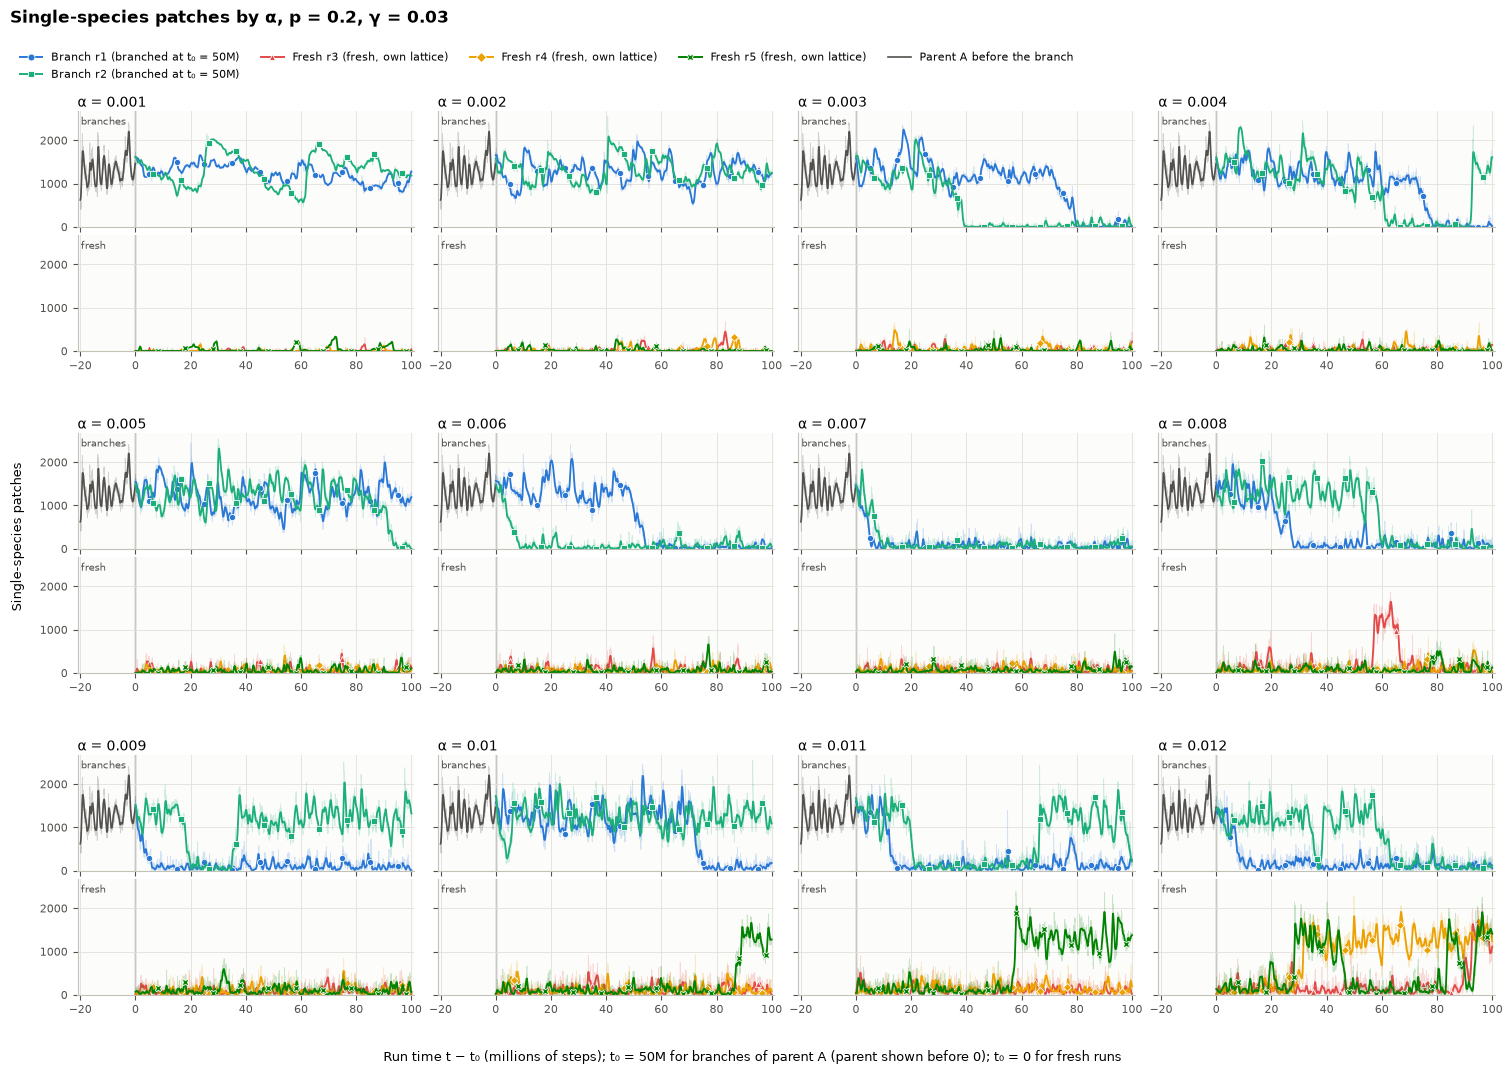

In [4]:
plot_trajectories("alpha", "patches", "Single-species patches")

## 3. α sweep: every run at a glance

One row per run, coloured by living species, on run time. Rows are grouped by α, and the symbol at the
start of each row gives the run's identity. The colour scale is square-root, so low counts (1-10 species)
stay visible next to the diverse state. This view shows when each collapse or emergence happens and
whether it lasts.

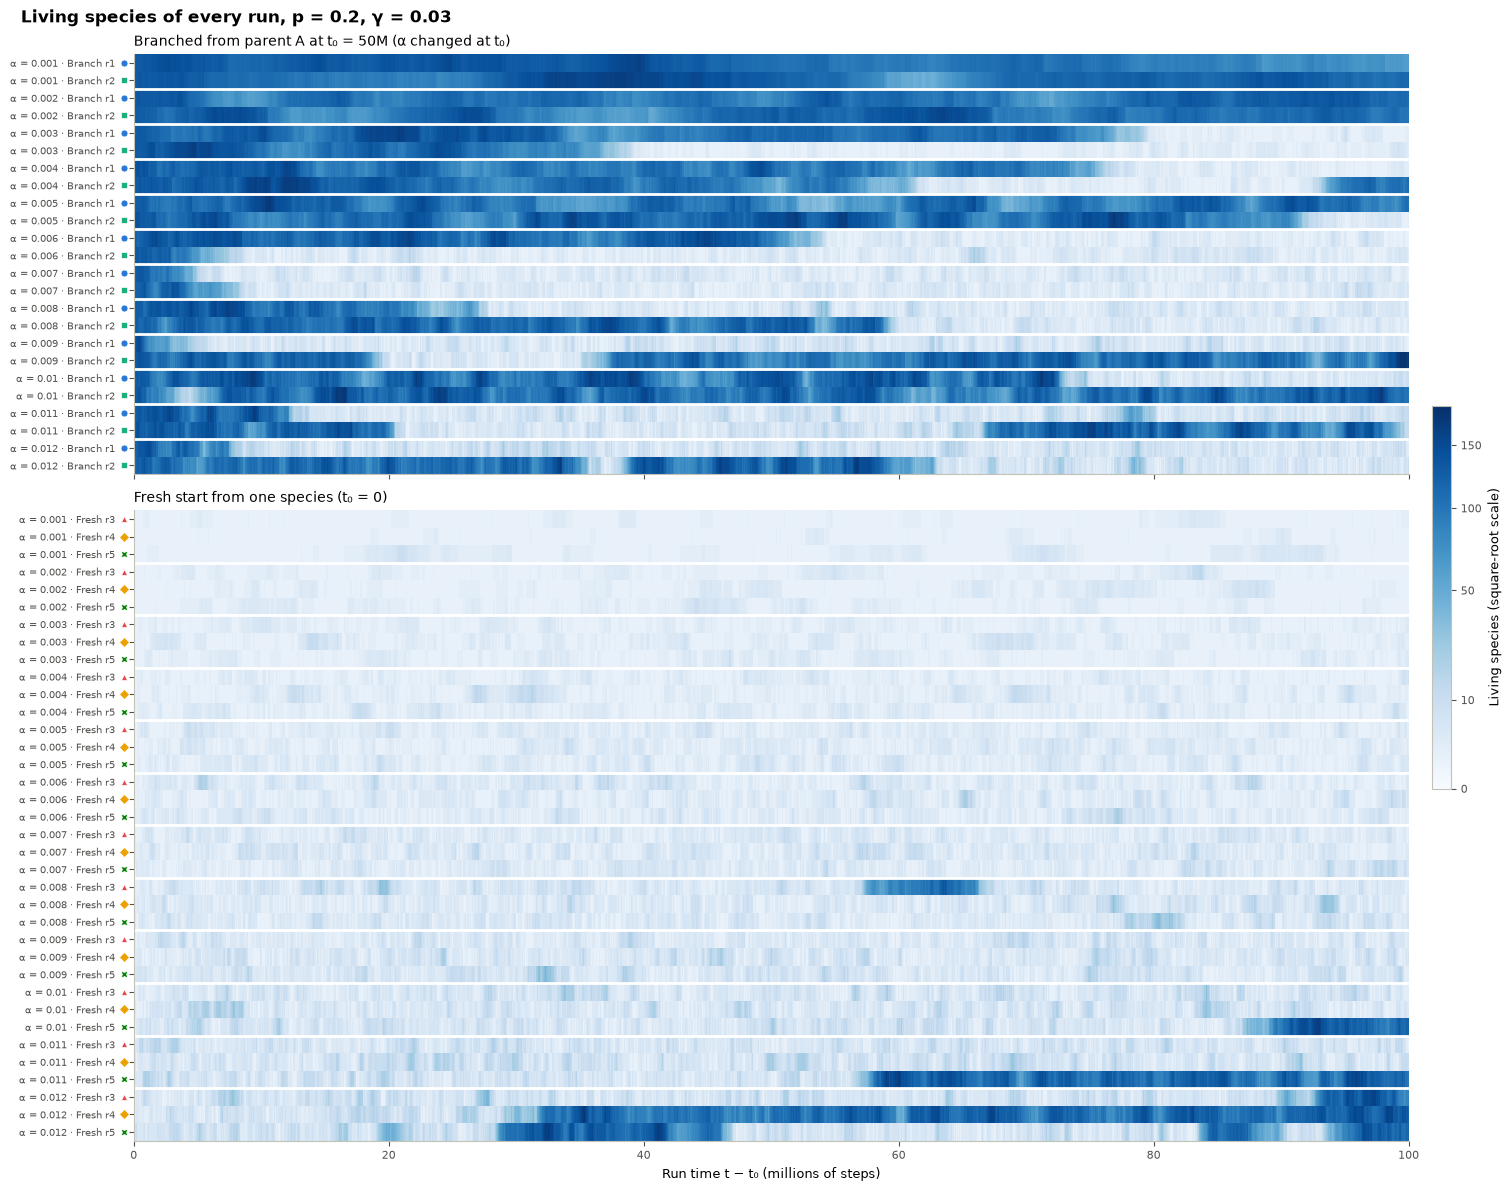

In [5]:
def plot_raster(experiment):
    runs = [run for run in all_runs if run["experiment"] == experiment]
    groups = [group for group in ("branch", "fresh") if any(run["group"] == group for run in runs)]
    panels = [sorted((run for run in runs if run["group"] == group),
                     key=lambda run: (run["value"], run["repeat"])) for group in groups]
    vmax = max(run["diversity"].max() for run in runs)
    sym = SYMBOL[experiment]
    with plt.rc_context(RESULT_STYLE):
        fig, axes = plt.subplots(len(groups), 1, figsize=(15, 0.15 * len(runs) + 0.9 * len(groups) + 1),
                                 sharex=True, squeeze=False, layout="constrained",
                                 gridspec_kw={"height_ratios": [len(panel) for panel in panels]})
        for ax, members in zip(axes[:, 0], panels):
            width = max(run["diversity"].size for run in members)
            rows = np.full((len(members), width), np.nan)
            for row, run in zip(rows, members):
                row[:run["diversity"].size] = run["diversity"]
            longest = max(members, key=lambda run: run["diversity"].size)["elapsed"]
            image = ax.imshow(rows, aspect="auto", interpolation="nearest", cmap="Blues",
                              norm=PowerNorm(0.5, vmin=0, vmax=vmax),
                              extent=(longest[0], longest[-1], len(members) - 0.5, -0.5))
            ax.set_yticks(range(len(members)), [f"{sym} = {run['value']:g} · {run['name']}"
                                                for run in members], fontsize=7)
            for index, run in enumerate(members):  # Identity symbol just left of each row.
                ax.plot(-0.008, index, marker=run["marker"], color=run["color"], ms=5,
                        mec="white", mew=0.5, transform=ax.get_yaxis_transform(), clip_on=False)
                if index and run["value"] != members[index - 1]["value"]:
                    ax.axhline(index - 0.5, color="white", lw=2)
            ax.tick_params(axis="y", pad=10)
            ax.grid(False)
            ax.set_title(_group_title(members[0]))
        axes[-1, 0].set_xlabel("Run time t − t₀ (millions of steps)")
        colorbar = fig.colorbar(image, ax=axes[:, 0], label="Living species (square-root scale)",
                                fraction=0.015, pad=0.01)
        colorbar.set_ticks([0, LOW, HIGH, 100, 150])
        fig.suptitle(f"Living species of every run, {_experiment_title(experiment)}", x=0.01,
                     ha="left", fontsize=12, fontweight="bold")
        plt.show()


plot_raster("alpha")

## 4. α sweep: where each start ends up

Each marker is one run, in its own colour and shape, offset slightly in α so runs at the same α do not
overlap. There are no group means or error bands. With two or three runs per α, and siblings that often
end in opposite states, a mean would show a value no run held. The hollow circle is parent A over 25-50M
(a reference, not a control; see section 2).

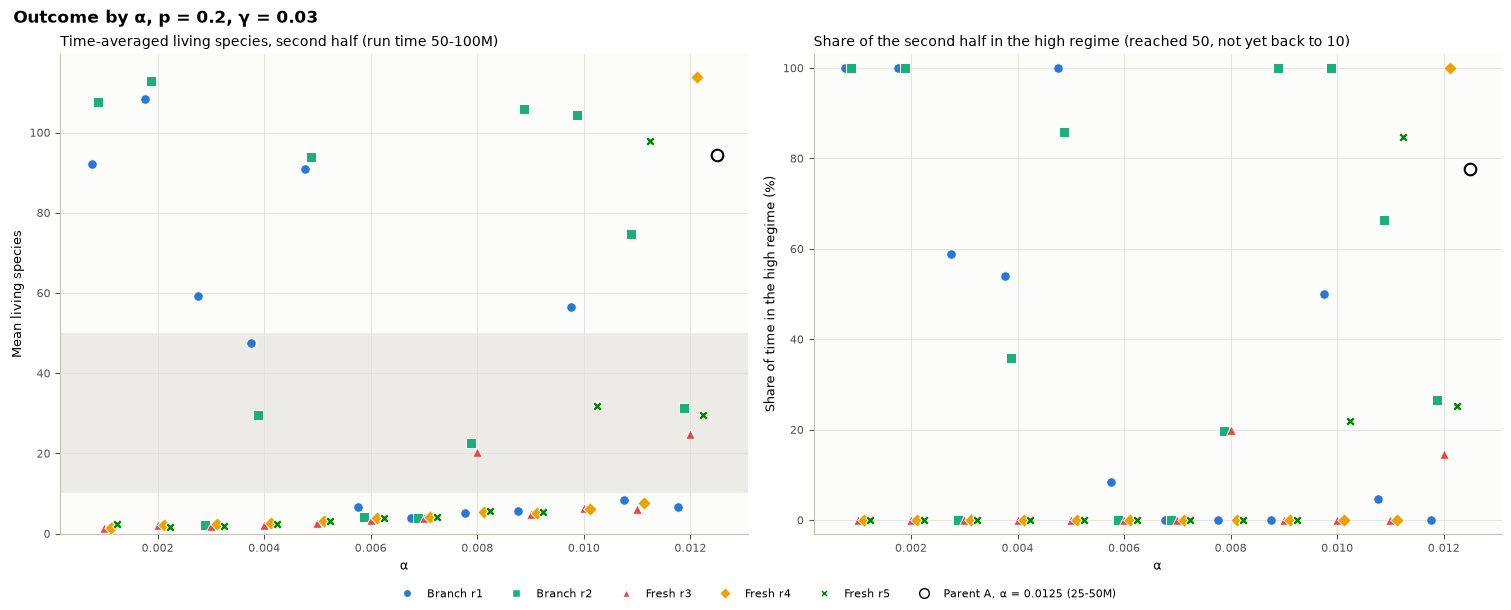

In [6]:
def _offsets(runs):
    identities = sorted({run["repeat"] for run in runs})
    values = sorted({run["value"] for run in runs})
    step = np.min(np.diff(values)) if len(values) > 1 else 1.0
    spread = np.linspace(-1, 1, len(identities)) * 0.24 * step if len(identities) > 1 else [0.0]
    return dict(zip(identities, spread))


def _summary_axes(experiment, axes, fields):
    """Per-run markers plus parent and grid references on each (axis, field)."""
    runs = [run for run in all_runs if run["experiment"] == experiment]
    offsets = _offsets(runs)
    parent = next(parents[run["parent"]] for run in runs if run["parent"])
    for ax, field in zip(axes, fields):
        scale = 100 if field == "share_high" else 1
        for run in runs:
            ax.scatter(run["value"] + offsets[run["repeat"]], scale * run[field], s=48,
                       color=run["color"], marker=run["marker"], edgecolors="white",
                       linewidths=0.7, zorder=4)
            if run["parent"] and np.isclose(run["value"], parent[experiment]):
                ax.annotate("control\n(unchanged)", (run["value"], scale * run[field]),
                            xytext=(8, -4), textcoords="offset points", fontsize=7.5,
                            color=PARENT_COLOR, va="top")
        ax.scatter(parent[experiment], scale * parent[field], s=70, facecolors="white",
                   edgecolors="black", linewidths=1.5, zorder=5)
        if experiment == "gamma":
            for ref in grid_refs:
                ax.scatter(ref["value"], scale * ref[field], s=60, marker="s", facecolors="none",
                           edgecolors=PARENT_COLOR, linewidths=1.4, zorder=5)


def _summary_legend(experiment):
    runs = [run for run in all_runs if run["experiment"] == experiment]
    handles = [Line2D([], [], color=color, marker=marker, lw=0, ms=6, mec="white", label=name)
               for _, name, color, marker in sorted({(run["repeat"], run["name"], run["color"],
                                                      run["marker"]) for run in runs})]
    parent = next(parents[run["parent"]] for run in runs if run["parent"])
    handles.append(Line2D([], [], color="black", marker="o", mfc="white", lw=0, ms=7,
                          label=f"Parent {parent['letter']}, {SYMBOL[experiment]} = "
                                f"{parent[experiment]:g} (25-50M)"))
    if experiment == "gamma" and grid_refs:
        handles.append(Line2D([], [], color=PARENT_COLOR, marker="s", mfc="white", lw=0, ms=7,
                              label="Grid runs from one species, own lattice (25-50M)"))
    return handles


def plot_summary(experiment):
    sym = SYMBOL[experiment]
    with plt.rc_context(RESULT_STYLE):
        fig, (ax_mean, ax_share) = plt.subplots(1, 2, figsize=(15, 6.0), layout="constrained")
        ax_mean.axhspan(LOW, HIGH, color=BAND_COLOR, lw=0, zorder=0)
        _summary_axes(experiment, (ax_mean, ax_share), ("mean", "share_high"))
        ax_mean.set(xlabel=sym, ylabel="Mean living species",
                    title="Time-averaged living species, second half (run time 50-100M)")
        ax_share.set(xlabel=sym, ylabel="Share of time in the high regime (%)",
                     title=f"Share of the second half in the high regime (reached {HIGH}, "
                           f"not yet back to {LOW})")
        ax_mean.set_ylim(bottom=0)
        ax_share.set_ylim(-3, 103)
        handles = _summary_legend(experiment)
        fig.legend(handles=handles, loc="outside lower center", ncols=len(handles))
        fig.suptitle(f"Outcome by {sym}, {_experiment_title(experiment)}", x=0.005, ha="left",
                     fontsize=12, fontweight="bold")
        plt.show()


plot_summary("alpha")

## 5. α sweep: how living species are distributed

The share of each run's second half spent at each species count, in 5-species bins and on a logarithmic
colour scale, so short visits still show. Each α has one narrow column per run, marked at the top with
the run's symbol (left to right: r1, r2 for branches; r3, r4, r5 for fresh runs). A single column with
bands both below `LOW` and above `HIGH` (dotted lines) is a run that spent time in both regimes. Columns
that differ at the same α are runs that ended in different states. Empty cells take the background
colour.

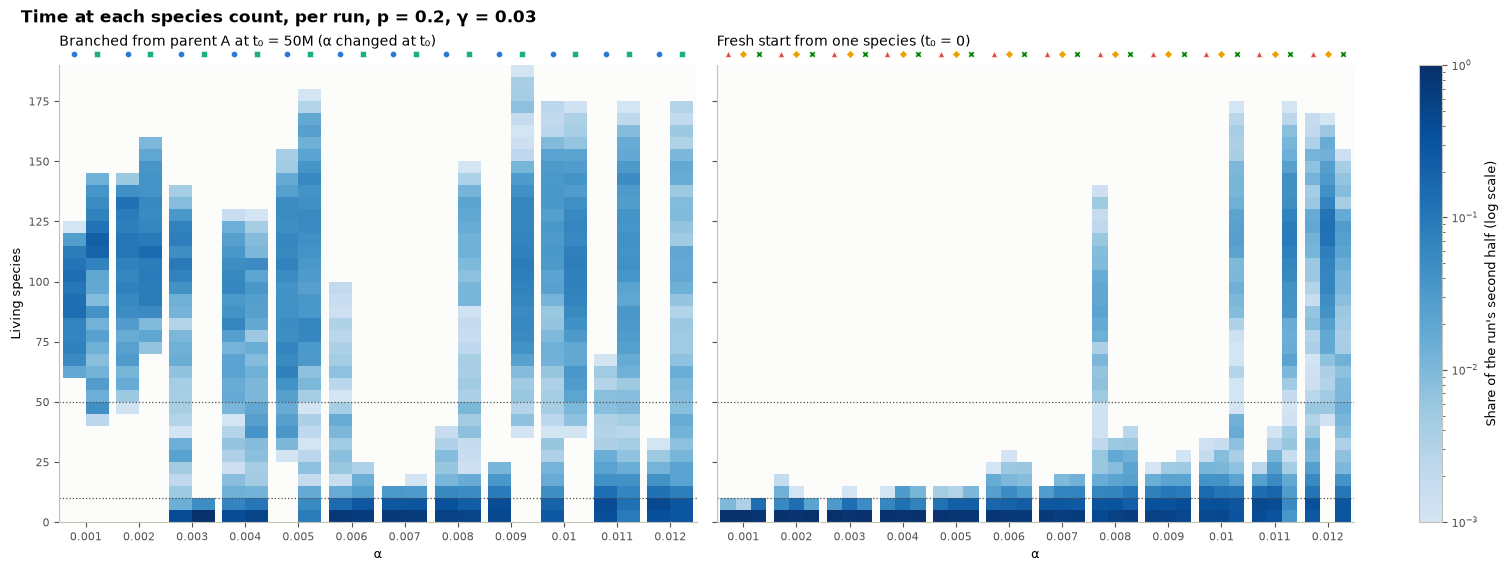

In [7]:
def plot_distributions(experiment):
    runs = [run for run in all_runs if run["experiment"] == experiment]
    groups = [group for group in ("branch", "fresh") if any(run["group"] == group for run in runs)]
    edges = np.arange(0, max(run["late"].max() for run in runs) + 6, 5)
    cmap = ListedColormap(plt.colormaps["Blues"](np.linspace(0.18, 1.0, 256)))
    norm = LogNorm(vmin=1e-3, vmax=1)
    sym = SYMBOL[experiment]
    with plt.rc_context(RESULT_STYLE):
        fig, axes = plt.subplots(1, len(groups), figsize=(15 if len(groups) > 1 else 9, 5.6),
                                 sharey=True, squeeze=False, layout="constrained")
        for ax, group in zip(axes[0], groups):
            members = [run for run in runs if run["group"] == group]
            values = sorted({run["value"] for run in members})
            for index, value in enumerate(values):
                column = sorted((run for run in members if run["value"] == value),
                                key=lambda run: run["repeat"])
                width = 0.86 / len(column)
                for slot, run in enumerate(column):
                    left = index - 0.43 + slot * width
                    shares = np.histogram(run["late"], bins=edges)[0] / run["late"].size
                    mesh = ax.pcolormesh([left, left + width], edges,
                                         np.ma.masked_equal(shares, 0)[:, None], cmap=cmap, norm=norm)
                    ax.plot(left + width / 2, edges[-1] + 0.025 * edges[-1], marker=run["marker"],
                            color=run["color"], ms=4.5, mec="white", mew=0.4, clip_on=False)
            for level in (LOW, HIGH):
                ax.axhline(level, color=PARENT_COLOR, ls=":", lw=0.9)
            ax.set_xticks(range(len(values)), [f"{value:g}" for value in values])
            ax.set_xlim(-0.5, len(values) - 0.5)
            ax.set_ylim(0, edges[-1])
            ax.grid(False)
            ax.set_xlabel(sym)
            ax.set_title(_group_title(members[0]), pad=14)
        axes[0, 0].set_ylabel("Living species")
        fig.colorbar(mesh, ax=axes[0], label="Share of the run's second half (log scale)")
        fig.suptitle(f"Time at each species count, per run, {_experiment_title(experiment)}",
                     x=0.01, ha="left", fontsize=12, fontweight="bold")
        plt.show()


plot_distributions("alpha")

## 6. α sweep: when runs switch regime

Left: the run time of each run's first switch. For a run that starts high (a branch) this is its first
collapse to `LOW`; for a run that starts low (a fresh run) it is its first rise to `HIGH`. Hollow markers
on the dotted line are runs that never switched. Right: the number of regime switches per run. Many
switches mean the run flickers between the two states.

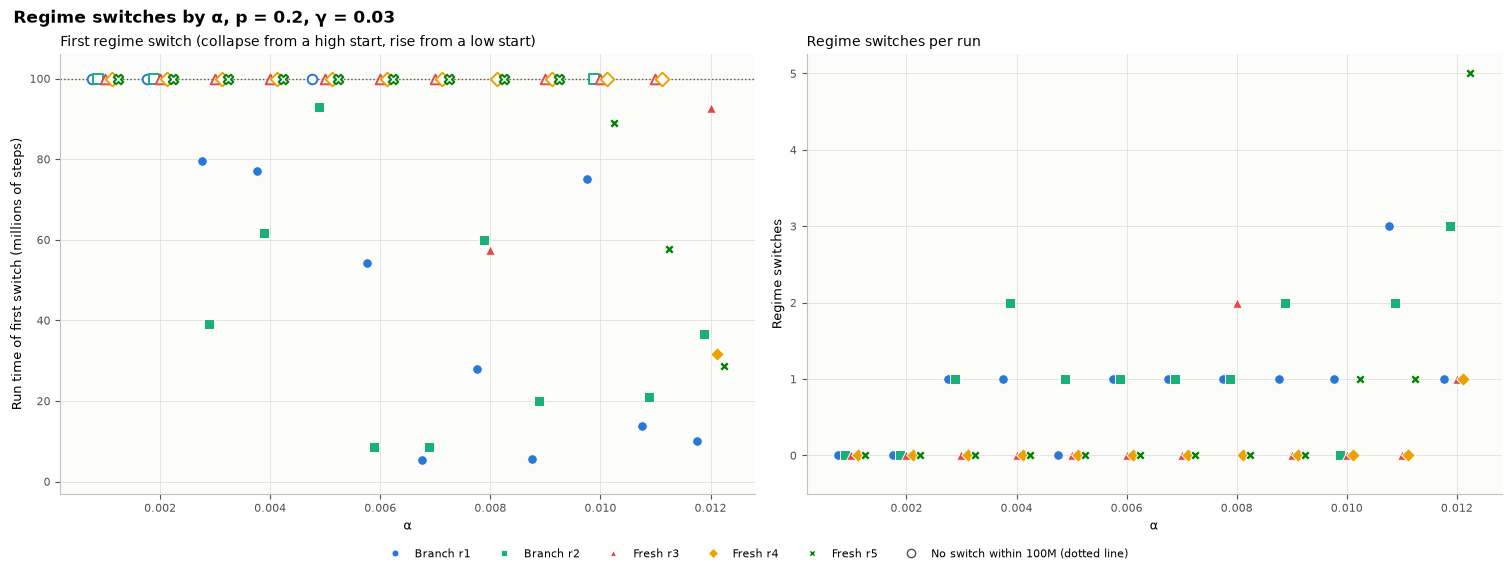

In [8]:
def plot_switches(experiment):
    runs = [run for run in all_runs if run["experiment"] == experiment]
    offsets = _offsets(runs)
    sym = SYMBOL[experiment]
    run_length = max(run["length"] for run in runs) / 1e6
    with plt.rc_context(RESULT_STYLE):
        fig, (ax_first, ax_count) = plt.subplots(1, 2, figsize=(15, 5.6), layout="constrained")
        for run in runs:
            x = run["value"] + offsets[run["repeat"]]
            switched = run["switch_elapsed"].size > 0
            ax_first.scatter(x, run["switch_elapsed"][0] if switched else run_length, s=48,
                             marker=run["marker"], zorder=4,
                             color=run["color"] if switched else "white",
                             edgecolors="white" if switched else run["color"],
                             linewidths=0.7 if switched else 1.4)
            ax_count.scatter(x, run["switch_elapsed"].size, s=48, color=run["color"],
                             marker=run["marker"], edgecolors="white", linewidths=0.7, zorder=4)
        ax_first.axhline(run_length, color=PARENT_COLOR, ls=END_OF_RUN_LS, lw=1)
        ax_first.set(xlabel=sym, ylabel="Run time of first switch (millions of steps)",
                     title="First regime switch (collapse from a high start, rise from a low start)")
        ax_first.set_ylim(-3, run_length * 1.06)
        ax_count.set(xlabel=sym, ylabel="Regime switches", title="Regime switches per run")
        ax_count.set_ylim(bottom=-0.5)
        ax_count.yaxis.get_major_locator().set_params(integer=True)
        handles = _identity_handles(runs, detail=False)
        for handle in handles:
            handle.set_linestyle("none")
        handles.append(Line2D([], [], color=PARENT_COLOR, marker="o", mfc="white", lw=0, ms=6,
                              label=f"No switch within {run_length:g}M (dotted line)"))
        fig.legend(handles=handles, loc="outside lower center", ncols=len(handles))
        fig.suptitle(f"Regime switches by {sym}, {_experiment_title(experiment)}", x=0.005,
                     ha="left", fontsize=12, fontweight="bold")
        plt.show()


plot_switches("alpha")

## 7. α sweep: per-run table

`<LOW`, `LOW-HIGH` and `>HIGH` are shares of the raw second-half samples. `high` is the share in the
high regime (smoothed rule). `switch` counts regime switches, `first` is the run time of the first one,
and `final` is the number of living species at the end.

In [9]:
def print_table(experiment):
    runs = [run for run in all_runs if run["experiment"] == experiment]
    sym = SYMBOL[experiment]
    print(f"{'run':>9} {sym:>6} {'mean':>7} {f'<{LOW}':>5} {f'{LOW}-{HIGH}':>6} {f'>{HIGH}':>5} "
          f"{'high':>5} {'switch':>6} {'first':>7} {'final':>6}")
    for run in sorted(runs, key=lambda run: (run["value"], run["repeat"])):
        late = run["late"]
        first = (f"{run['switch_elapsed'][0]:6.1f}M" if run["switch_elapsed"].size
                 else f"{'-':>7}")
        print(f"{run['name']:>9} {run['value']:6.3f} {run['mean']:7.1f} {np.mean(late < LOW):5.0%} "
              f"{np.mean((late >= LOW) & (late <= HIGH)):6.0%} {np.mean(late > HIGH):5.0%} "
              f"{run['share_high']:5.0%} {run['switch_elapsed'].size:6d} {first} {run['final']:6d}")


print_table("alpha")

      run      α    mean   <10  10-50   >50  high switch   first  final
Branch r1  0.001    92.1    0%     0%  100%  100%      0       -     61
Branch r2  0.001   107.6    0%     5%   95%  100%      0       -    116
 Fresh r3  0.001     1.3  100%     0%    0%    0%      0       -      3
 Fresh r4  0.001     1.3  100%     0%    0%    0%      0       -      1
 Fresh r5  0.001     2.3  100%     0%    0%    0%      0       -      1
Branch r1  0.002   108.4    0%     0%  100%  100%      0       -    110
Branch r2  0.002   113.0    0%     0%  100%  100%      0       -    101
 Fresh r3  0.002     2.0   98%     2%    0%    0%      0       -      1
 Fresh r4  0.002     2.2  100%     0%    0%    0%      0       -      1
 Fresh r5  0.002     1.6  100%     0%    0%    0%      0       -      1
Branch r1  0.003    59.2   41%     6%   53%   59%      1   79.5M      2
Branch r2  0.003     2.1  100%     0%    0%    0%      1   39.0M      2
 Fresh r3  0.003     1.9  100%     0%    0%    0%      0       -

## 8. α sweep: final lattices of the branches

The newest saved state (t = 150M) of every run that kept checkpoints. This covers both branch repeats;
the fresh runs were copied back without lattices. Black = blocked, light grey = empty, other colours =
species, and the frame colour gives the run. A species' colour comes from its ID, so colours are
consistent within one run only. Sibling branches number their new species the same way, so the same
colour in two images does not mean the same species. No species from before the branch survives in any
final state (see the tables in section 9).

No lattice checkpoints, so not shown: Fresh r3, Fresh r4, Fresh r5


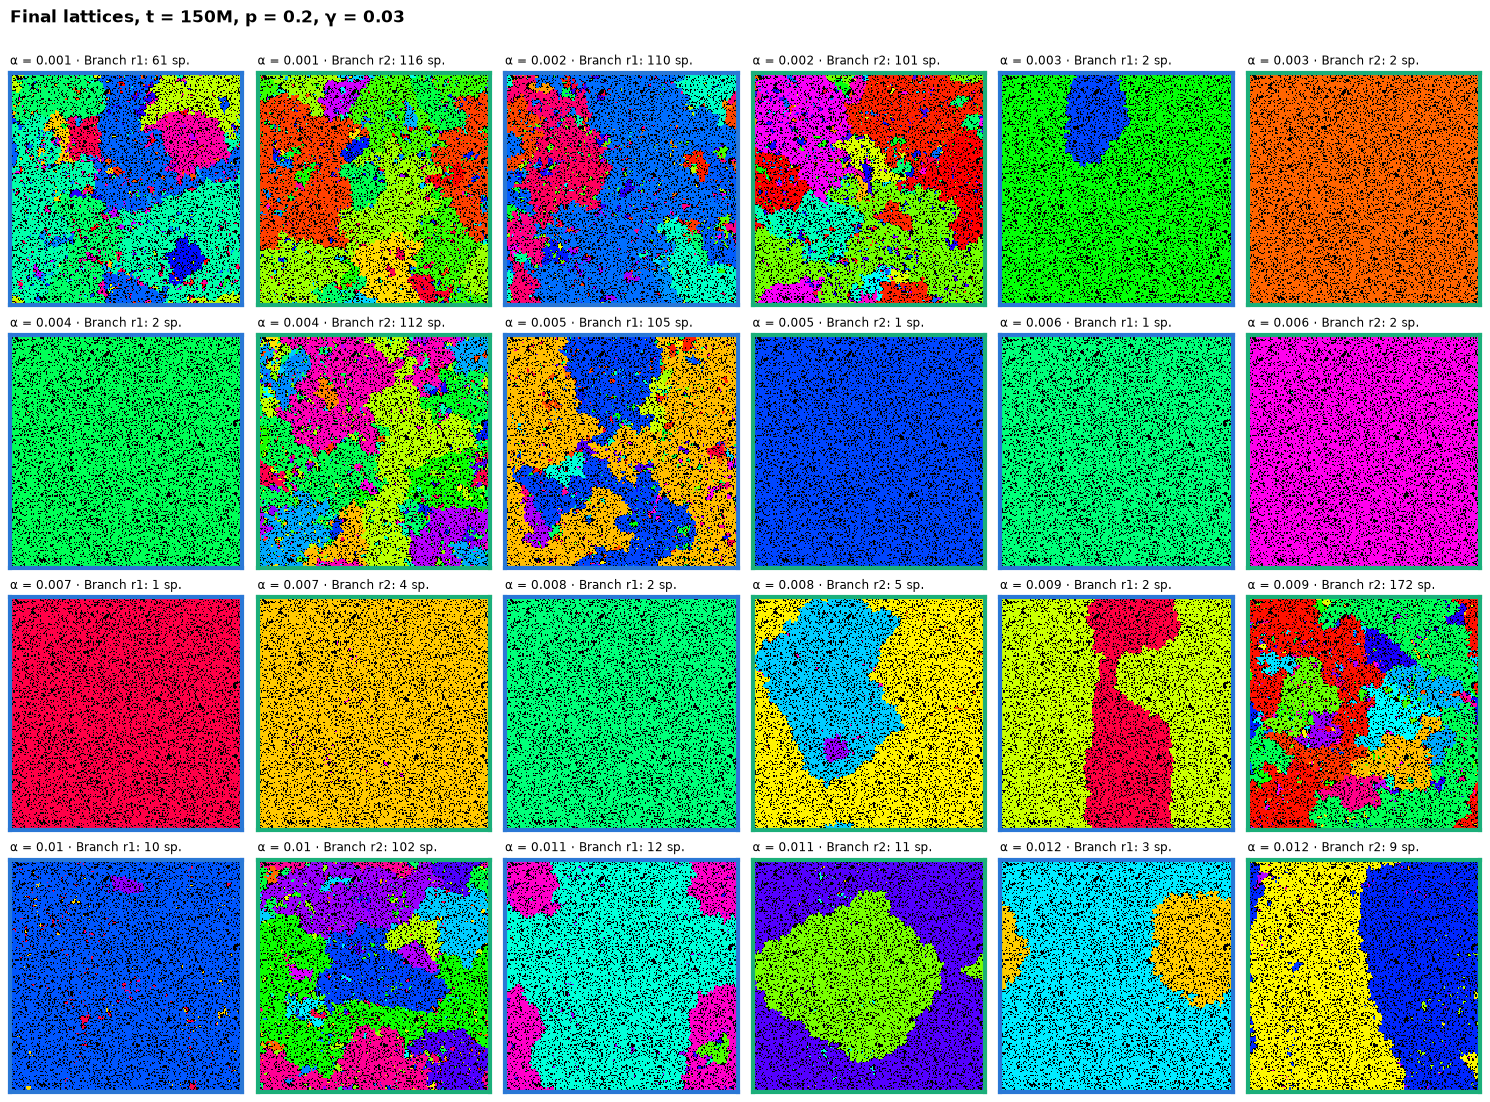

In [10]:
def load_final_states(experiment):
    runs = sorted((run for run in all_runs if run["experiment"] == experiment and run["has_checkpoints"]),
                  key=lambda run: (run["value"], run["repeat"]))
    return [(run, MS.load_checkpoint(run["checkpoint_dir"])) for run in runs]


def plot_final_lattices(experiment, finals, ncols):
    missing = sorted({run["name"] for run in all_runs
                      if run["experiment"] == experiment and not run["has_checkpoints"]})
    if missing:
        print("No lattice checkpoints, so not shown: " + ", ".join(missing))
    sym = SYMBOL[experiment]
    nrows = -(-len(finals) // ncols)
    with plt.rc_context(RESULT_STYLE):
        fig, axes = plt.subplots(nrows, ncols, figsize=(15, (15 / ncols) * 1.08 * nrows + 0.5),
                                 squeeze=False)
        for ax, (run, state) in zip(axes.flat, finals):
            ax.imshow(MS._lattice_rgba(state["lattice"]), interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_edgecolor(run["color"])
                spine.set_linewidth(3)
            ax.set_title(f"{sym} = {run['value']:g} · {run['name']}: {state['diversity']} sp.",
                         fontsize=8.5)
        for ax in axes.flat[len(finals):]:
            ax.set_visible(False)
        times = sorted({state["timestep"] for _, state in finals})
        fig.suptitle(f"Final lattices, t = {', '.join(f'{t / 1e6:g}M' for t in times)}, "
                     f"{_experiment_title(experiment)}", x=0.01, ha="left", fontsize=12,
                     fontweight="bold")
        fig.tight_layout(rect=(0, 0, 1, 0.98))
        plt.show()


alpha_finals = load_final_states("alpha")
plot_final_lattices("alpha", alpha_finals, ncols=6)

## 9. α sweep: community structure of the final states

The table gives, for each final state:
- its number of species and the share of sites held by the largest one;
- how many species date from before the branch;
- how many species were introduced since the branch, next to the expected α·γ·T;
- the density of its invasion network Γ. Connectance is links / (S(S − 1)); compare it with γ, the
  chance that a link is drawn when a species arrives.

Species rank orders the species of one final state by the sites they hold, largest first (rank 1 = most
abundant). The rank-abundance panels cover every α where some final state has at least `LOW` species.
The connectance plot shows final states with at least 30 species; smaller ones rest on a handful of
links. The matrix is Γ of the most diverse final state, with species ordered by rank: row i invades
column j.

      run      α  species  largest pre-branch introduced   α·γ·T  links  connect.      γ
Branch r1  0.001       61    34.9%          0       2968    3000     86     0.023  0.030
Branch r2  0.001      116    29.1%          0       2907    3000    246     0.018  0.030
Branch r1  0.002      110    47.3%          0       6014    6000    212     0.018  0.030
Branch r2  0.002      101    27.5%          0       5932    6000    210     0.021  0.030
Branch r1  0.003        2    91.7%          0       9096    9000      0     0.000  0.030
Branch r2  0.003        2   100.0%          0       8848    9000      0     0.000  0.030
Branch r1  0.004        2   100.0%          0      11905   12000      0     0.000  0.030
Branch r2  0.004      112    18.2%          0      11895   12000    255     0.021  0.030
Branch r1  0.005      105    57.1%          0      15016   15000    234     0.021  0.030
Branch r2  0.005        1   100.0%          0      15245   15000      0       nan  0.030
Branch r1  0.006     

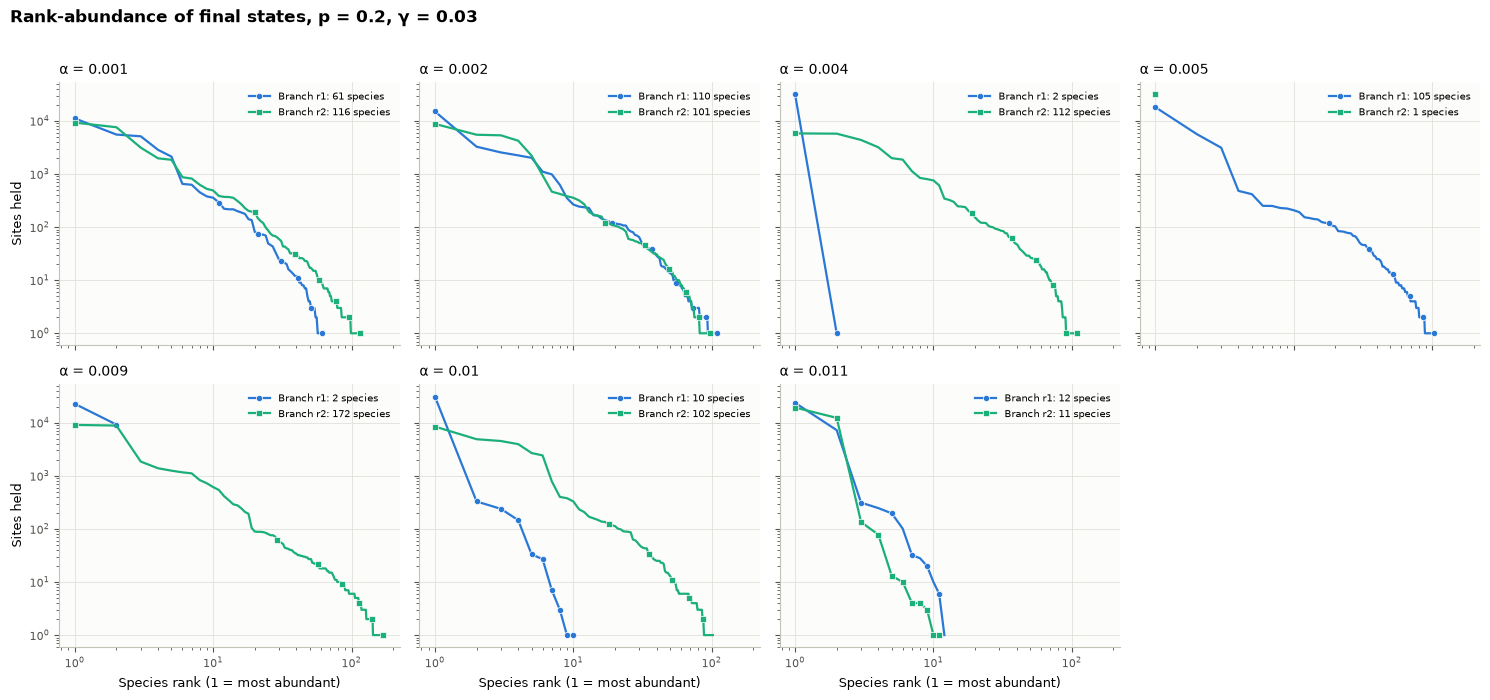

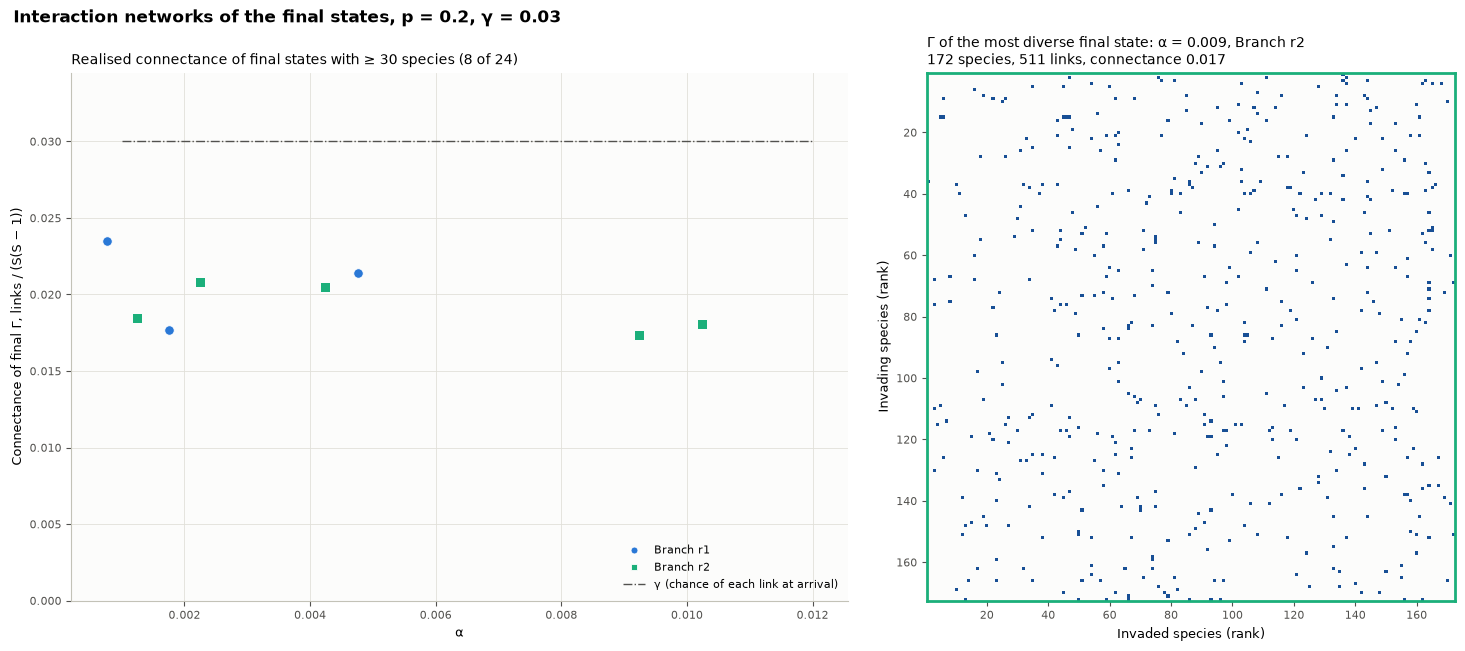

In [11]:
def community_structure(finals):
    structure = []
    for run, state in finals:
        lattice, Gamma = state["lattice"], np.asarray(state["Gamma"], dtype=np.int64)
        ids, sites = np.unique(lattice[lattice > 0], return_counts=True)
        held = dict(zip(ids.tolist(), sites.tolist()))
        species = np.asarray(state["current_species"])
        abundance = np.array([held.get(int(member), 0) for member in species])
        size = abundance.size
        links = int(Gamma.sum() - np.trace(Gamma))
        structure.append({
            "run": run, "Gamma": Gamma, "abundance": abundance, "species": size, "links": links,
            "largest": float(abundance.max() / abundance.sum()) if size else np.nan,
            "from_parent": int(np.sum(species <= int(state["initial_newest_species"]))),
            "introduced": int(state["newest_species"]) - int(state["initial_newest_species"]),
            "expected": run["alpha"] * run["gamma"] * run["length"],
            "connectance": links / (size * (size - 1)) if size > 1 else np.nan,
        })
    sym = SYMBOL[finals[0][0]["experiment"]]
    print(f"{'run':>9} {sym:>6} {'species':>8} {'largest':>8} {'pre-branch':>10} {'introduced':>10} "
          f"{'α·γ·T':>7} {'links':>6} {'connect.':>9} {'γ':>6}")
    for item in structure:
        run = item["run"]
        print(f"{run['name']:>9} {run['value']:6.3f} {item['species']:8d} {item['largest']:8.1%} "
              f"{item['from_parent']:10d} {item['introduced']:10d} {item['expected']:7.0f} "
              f"{item['links']:6d} {item['connectance']:9.3f} {run['gamma']:6.3f}")
    return structure


def plot_rank_abundance(structure):
    experiment = structure[0]["run"]["experiment"]
    sym = SYMBOL[experiment]
    values = sorted({item["run"]["value"] for item in structure if item["species"] >= LOW})
    if not values:
        print(f"No final state has {LOW} or more species.")
        return
    ncols = min(len(values), 4)
    nrows = -(-len(values) // ncols)
    with plt.rc_context(RESULT_STYLE):
        fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.1 * nrows + 0.9), sharex=True,
                                 sharey=True, squeeze=False)
        for ax, value in zip(axes.flat, values):
            for item in (item for item in structure if item["run"]["value"] == value):
                run = item["run"]
                ranked = np.sort(item["abundance"])[::-1]
                ax.plot(np.arange(1, ranked.size + 1), ranked, color=run["color"], lw=1.6,
                        marker=run["marker"], ms=4.5, mec="white", mew=0.5,
                        markevery=max(1, ranked.size // 6),
                        label=f"{run['name']}: {item['species']} species")
            ax.set(xscale="log", yscale="log", title=f"{sym} = {value:g}")
            ax.legend(loc="upper right", fontsize=7.5)
        for ax in axes.flat[len(values):]:
            ax.set_visible(False)
        for ax in axes[-1]:
            ax.set_xlabel("Species rank (1 = most abundant)")
        for ax in axes[:, 0]:
            ax.set_ylabel("Sites held")
        fig.suptitle(f"Rank-abundance of final states, {_experiment_title(experiment)}", x=0.01,
                     ha="left", fontsize=12, fontweight="bold")
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        plt.show()


def plot_network(structure):
    """Realised connectance of the larger final states, and Γ of the most diverse one."""
    experiment = structure[0]["run"]["experiment"]
    sym = SYMBOL[experiment]
    richest = max(structure, key=lambda item: item["species"])
    offsets = _offsets([item["run"] for item in structure])
    large = [item for item in structure if item["species"] >= CONNECTANCE_MIN_SPECIES]
    with plt.rc_context(RESULT_STYLE):
        fig, (ax_conn, ax_gamma) = plt.subplots(1, 2, figsize=(15, 6.4), layout="constrained",
                                                gridspec_kw={"width_ratios": [1.25, 1]})
        for item in large:
            run = item["run"]
            ax_conn.scatter(run["value"] + offsets[run["repeat"]], item["connectance"], s=48,
                            color=run["color"], marker=run["marker"], edgecolors="white",
                            linewidths=0.7, zorder=4)
        values = np.array(sorted({item["run"]["value"] for item in structure}))
        gammas = values if experiment == "gamma" else np.full(values.size, structure[0]["run"]["gamma"])
        ax_conn.plot(values, gammas, color=PARENT_COLOR, ls=GAMMA_LS, lw=1, label="γ")
        ax_conn.set(xlabel=sym, ylabel="Connectance of final Γ, links / (S(S − 1))",
                    title=f"Realised connectance of final states with ≥ {CONNECTANCE_MIN_SPECIES} "
                          f"species ({len(large)} of {len(structure)})")
        ax_conn.set_ylim(0, max(gammas.max(), max((item["connectance"] for item in large),
                                                  default=0)) * 1.15)
        handles = _identity_handles([item["run"] for item in large], detail=False)
        for handle in handles:
            handle.set_linestyle("none")
        handles.append(Line2D([], [], color=PARENT_COLOR, ls=GAMMA_LS, lw=1,
                              label="γ (chance of each link at arrival)"))
        ax_conn.legend(handles=handles, loc="lower right")
        order = np.argsort(-richest["abundance"], kind="stable")
        size = richest["species"]
        ax_gamma.imshow(richest["Gamma"][np.ix_(order, order)], interpolation="nearest",
                        cmap=ListedColormap([SURFACE, "#184f95"]), vmin=0, vmax=1,
                        extent=(0.5, size + 0.5, size + 0.5, 0.5))
        ax_gamma.grid(False)
        run = richest["run"]
        ax_gamma.set(xlabel="Invaded species (rank)", ylabel="Invading species (rank)",
                     title=f"Γ of the most diverse final state: {sym} = {run['value']:g}, "
                           f"{run['name']}\n{size} species, {richest['links']} links, "
                           f"connectance {richest['connectance']:.3f}")
        for spine in ax_gamma.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor(run["color"])
            spine.set_linewidth(2)
        fig.suptitle(f"Interaction networks of the final states, {_experiment_title(experiment)}",
                     x=0.005, ha="left", fontsize=12, fontweight="bold")
        plt.show()


alpha_structure = community_structure(alpha_finals)
plot_rank_abundance(alpha_structure)
plot_network(alpha_structure)

## 10. γ swap: living species over time

One branch of parent B per γ (p = 0.3, α = 0.0125). At 0, γ changes from 0.03 to the panel's value,
but only for species introduced from then on; the interactions already present are kept. Because new
species arrive at α·γ per time unit, a higher γ also means more frequent introductions, up to 5 × the
parent's rate at γ = 0.15. The γ = 0.03 run changes nothing and is the control: it shows parent B
continuing with a new random stream. There is one run per γ, so neighbouring panels also differ by
chance.

The living-species figure starts at run time `PLOT_FROM` (10M after the branch), leaving out parent B
and the first adjustment to the new γ. With `SHARE_Y = False` each panel's y-axis fits its own samples,
so the low-diversity runs are not flattened by the diverse ones. `PLOT_FROM = None` with
`SHARE_Y = True` shows parent B's last 20M steps before 0 on one shared axis. The second figure overlays
each γ's single-species patches (dashed, right axis) on its living species (solid, left axis) over the
runs' last 20M steps (from 80M). Only the smoothed lines are drawn, and with `SHARE_Y = False` each
axis runs from 0 to its own line's peak, so the two are scaled to match.

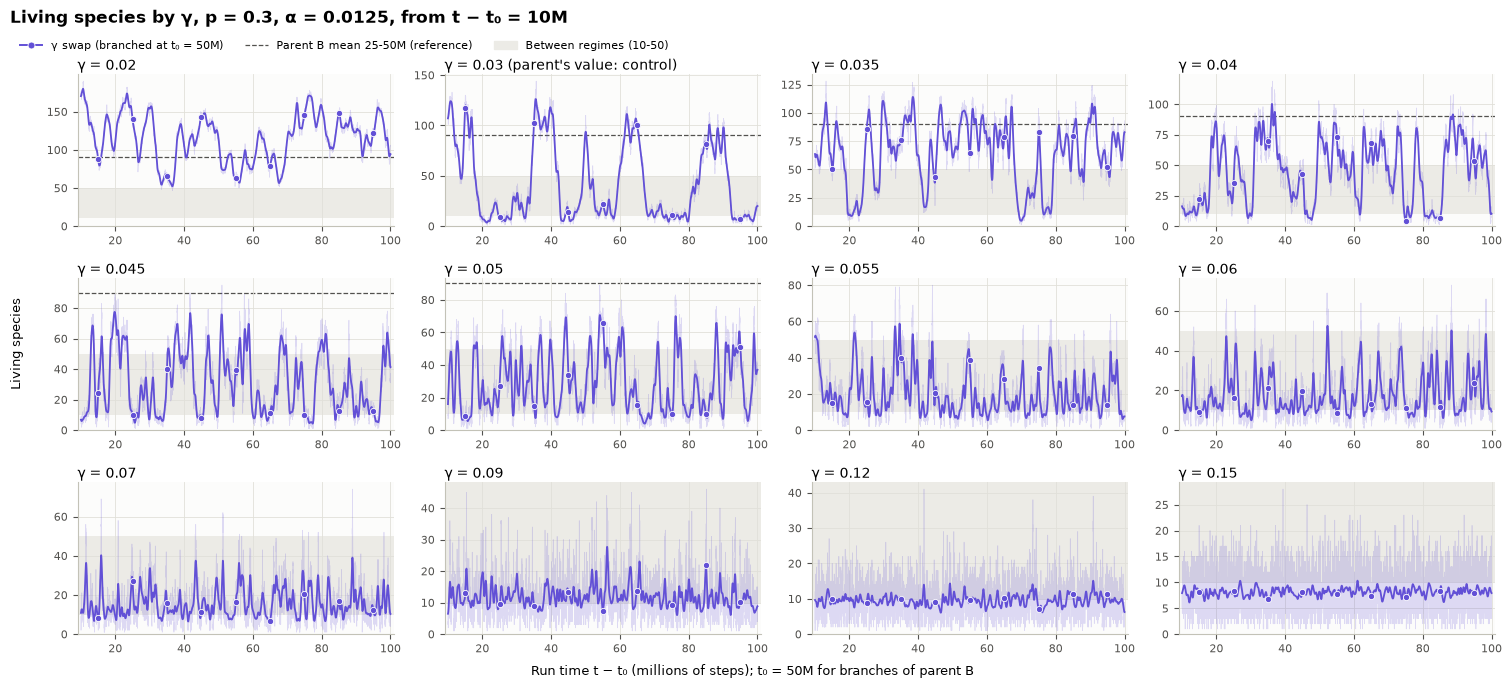

In [12]:
# Panels start at this run time t − t₀ (millions of steps, the x-axis; t₀ = 50M). From 0 on,
# parent B's history is left out; None starts 20M before the branch, with parent B.
PLOT_FROM = 10
SHARE_Y = False  # False: each panel's y-axis fits its own samples. True: one axis for all panels.
plot_trajectories("gamma", start=PLOT_FROM, share_y=SHARE_Y)

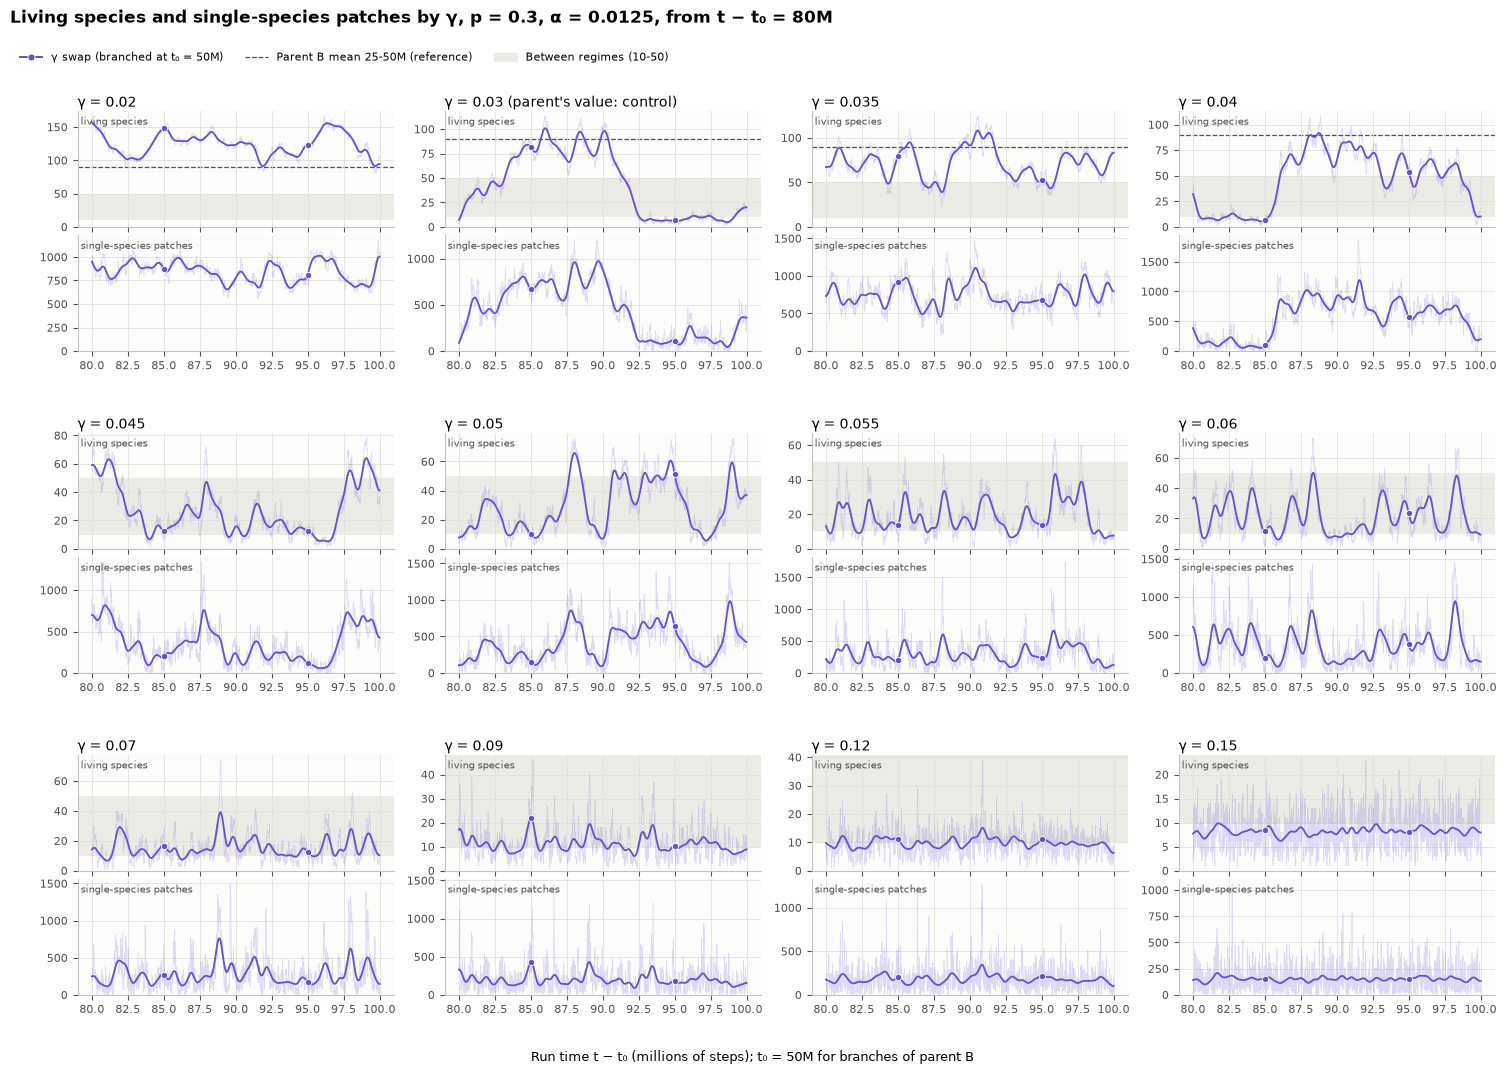

In [13]:
# Living species (solid, left axis) and single-species patches (dashed, right axis) overlaid for
# each γ, from 80M (the runs' last 20M steps). plot_trajectories("gamma", "patches") draws the
# patches alone.
plot_trajectories("gamma", ["diversity", "patches"], start=80, share_y=SHARE_Y)

## 11. γ swap: every run at a glance, outcome, and switching

The same views as for the α sweep. In the summaries, the hollow circle is parent B over 25-50M and the
labelled point is the control. The hollow squares are the p × γ grid runs at p = 0.3 that started from
one species on their own lattices: a fresh-start reference over 25-50M of a 50M run. The control itself
moves far from its parent (mean about 90 → 38 species, high-regime share 100% → 51%) without any
parameter change. With one run per γ, differences of that size between neighbouring γ values are not
evidence of a γ effect on their own.

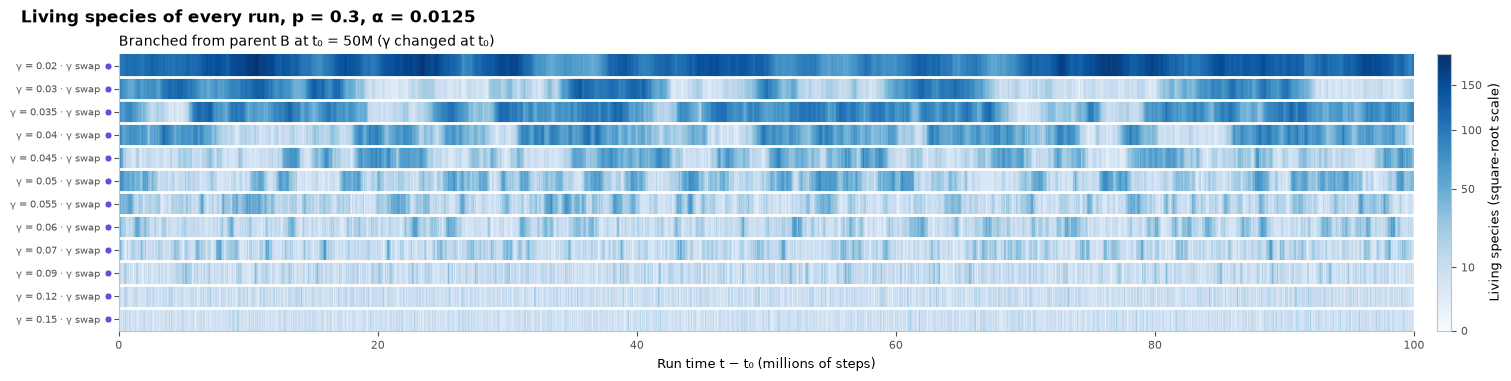

In [14]:
plot_raster("gamma")

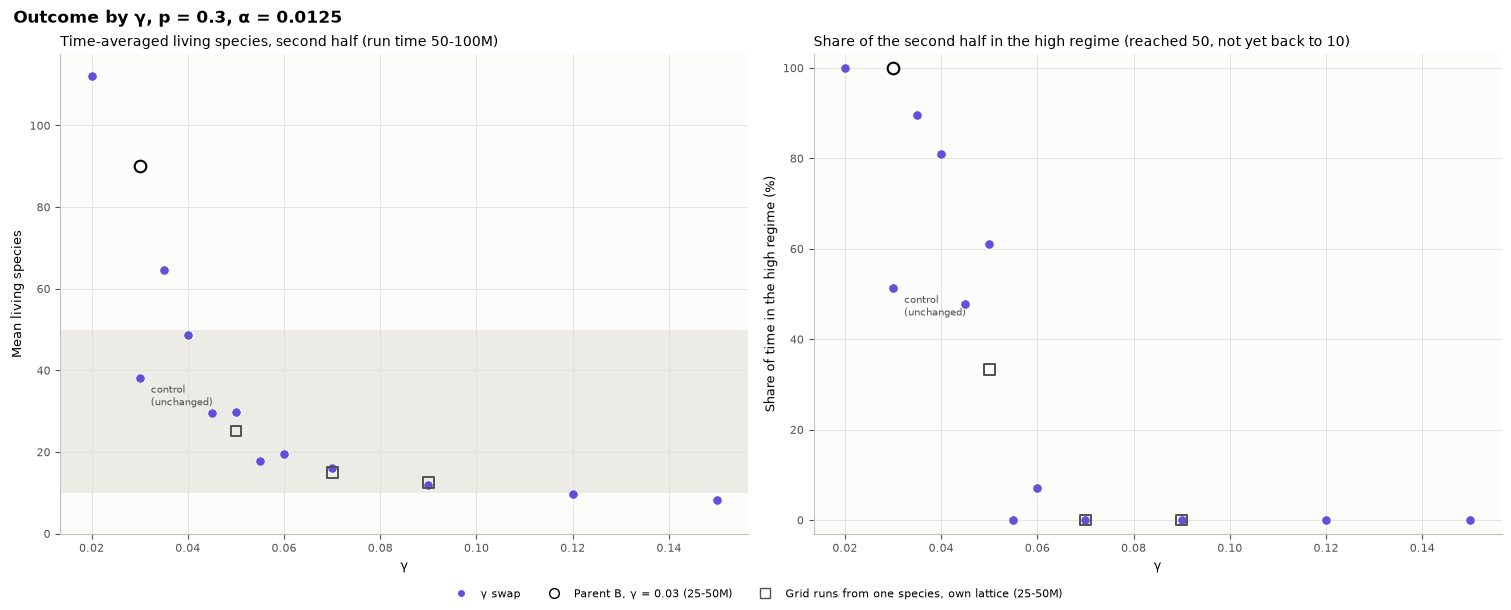

In [15]:
plot_summary("gamma")

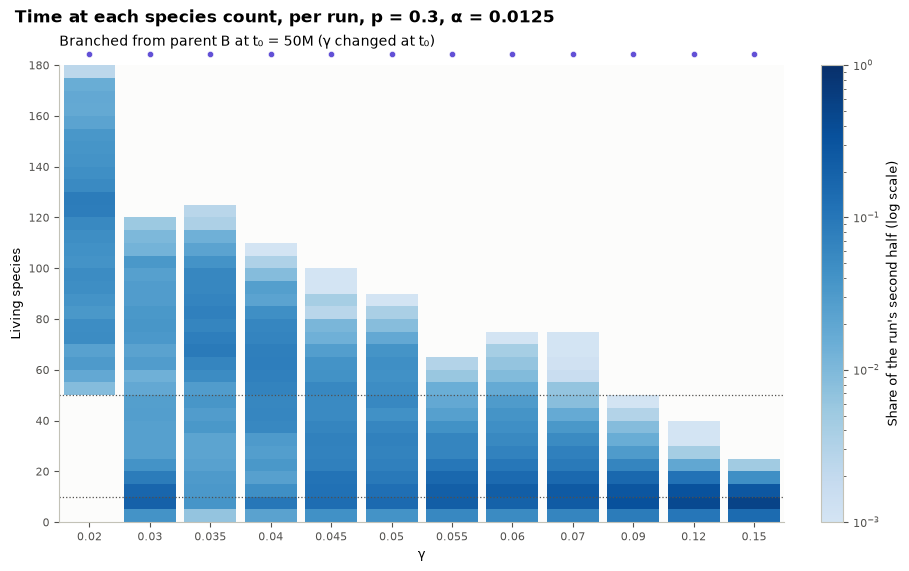

In [16]:
plot_distributions("gamma")

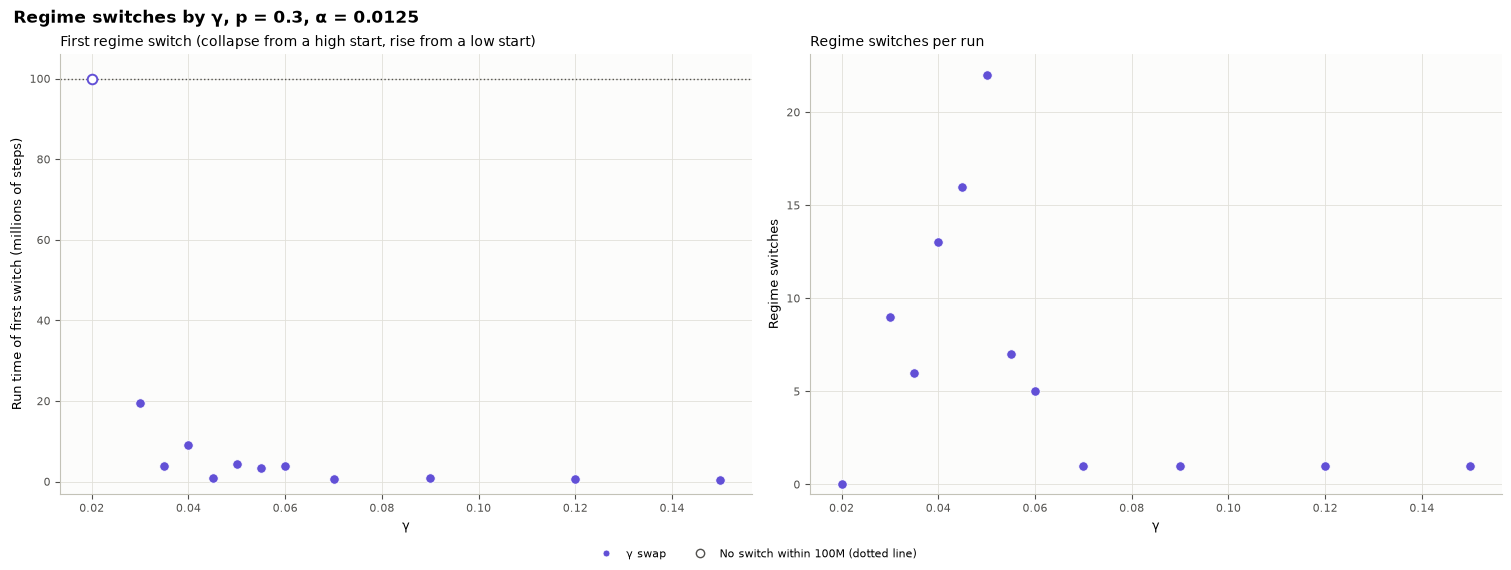

In [17]:
plot_switches("gamma")

In [18]:
print_table("gamma")

      run      γ    mean   <10  10-50   >50  high switch   first  final
   γ swap  0.020   112.2    0%     0%  100%  100%      0       -    105
   γ swap  0.030    38.1   24%    43%   33%   51%      9   19.4M     15
   γ swap  0.035    64.5    4%    24%   72%   90%      6    3.7M     93
   γ swap  0.040    48.7   12%    35%   52%   81%     13    9.0M     15
   γ swap  0.045    29.6   18%    64%   18%   48%     16    0.8M     32
   γ swap  0.050    29.7   19%    61%   20%   61%     22    4.4M     34
   γ swap  0.055    17.8   28%    69%    2%    0%      7    3.3M      8
   γ swap  0.060    19.5   25%    72%    3%    7%      5    3.9M      5
   γ swap  0.070    16.2   31%    68%    1%    0%      1    0.6M      7
   γ swap  0.090    12.0   43%    57%    0%    0%      1    0.8M     12
   γ swap  0.120     9.7   54%    46%    0%    0%      1    0.7M      5
   γ swap  0.150     8.2   67%    33%    0%    0%      1    0.5M      6


## 12. γ swap: final lattices and community structure

The final states at t = 150M and their networks. New links are drawn with the new γ, and new species
that would close a short cycle are redrawn. The dash-dot line marks connectance = γ.

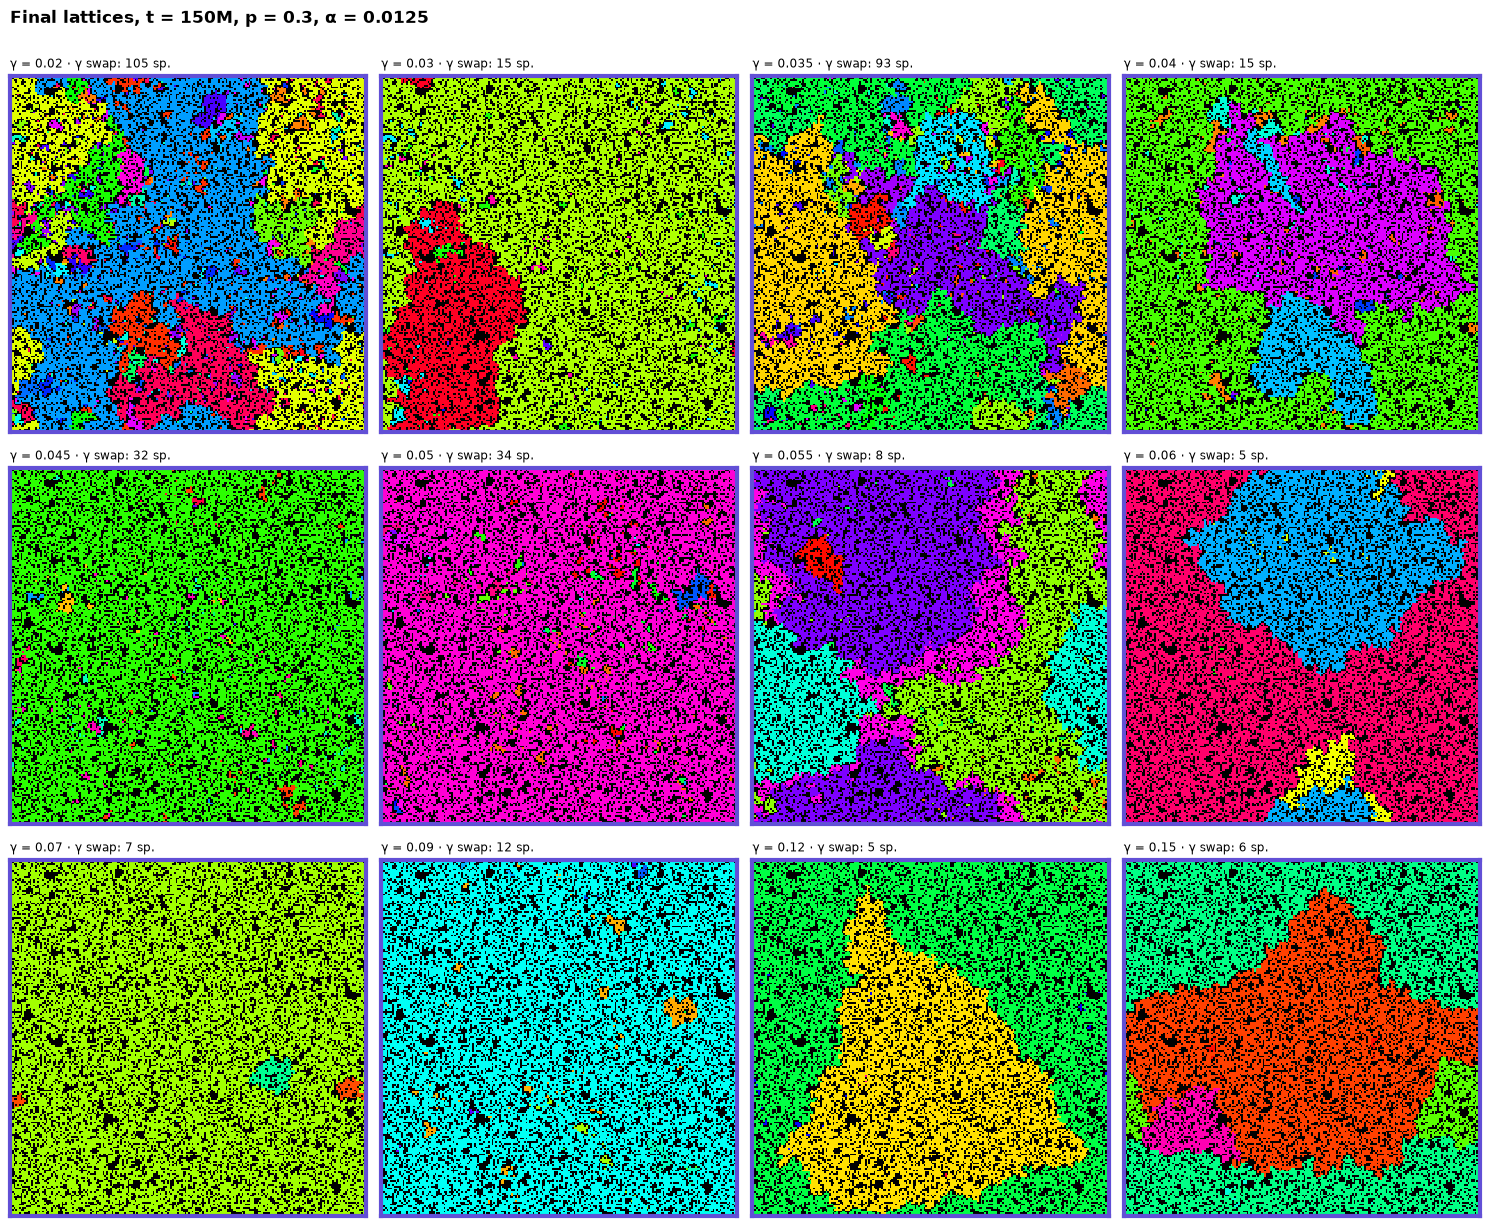

      run      γ  species  largest pre-branch introduced   α·γ·T  links  connect.      γ
   γ swap  0.020      105    41.1%          0      25189   25000    212     0.019  0.020
   γ swap  0.030       15    79.9%          0      37367   37500      6     0.029  0.030
   γ swap  0.035       93    31.8%          0      43843   43750    204     0.024  0.035
   γ swap  0.040       15    57.7%          0      50080   50000      6     0.029  0.040
   γ swap  0.045       32    96.6%          0      56358   56250     36     0.036  0.045
   γ swap  0.050       34    95.1%          0      62522   62500     46     0.041  0.050
   γ swap  0.055        8    39.0%          0      68733   68750      8     0.143  0.055
   γ swap  0.060        5    66.5%          0      75326   75000      2     0.100  0.060
   γ swap  0.070        7    98.5%          0      87251   87500      1     0.024  0.070
   γ swap  0.090       12    97.2%          0     112498  112500      8     0.061  0.090
   γ swap  0.120     

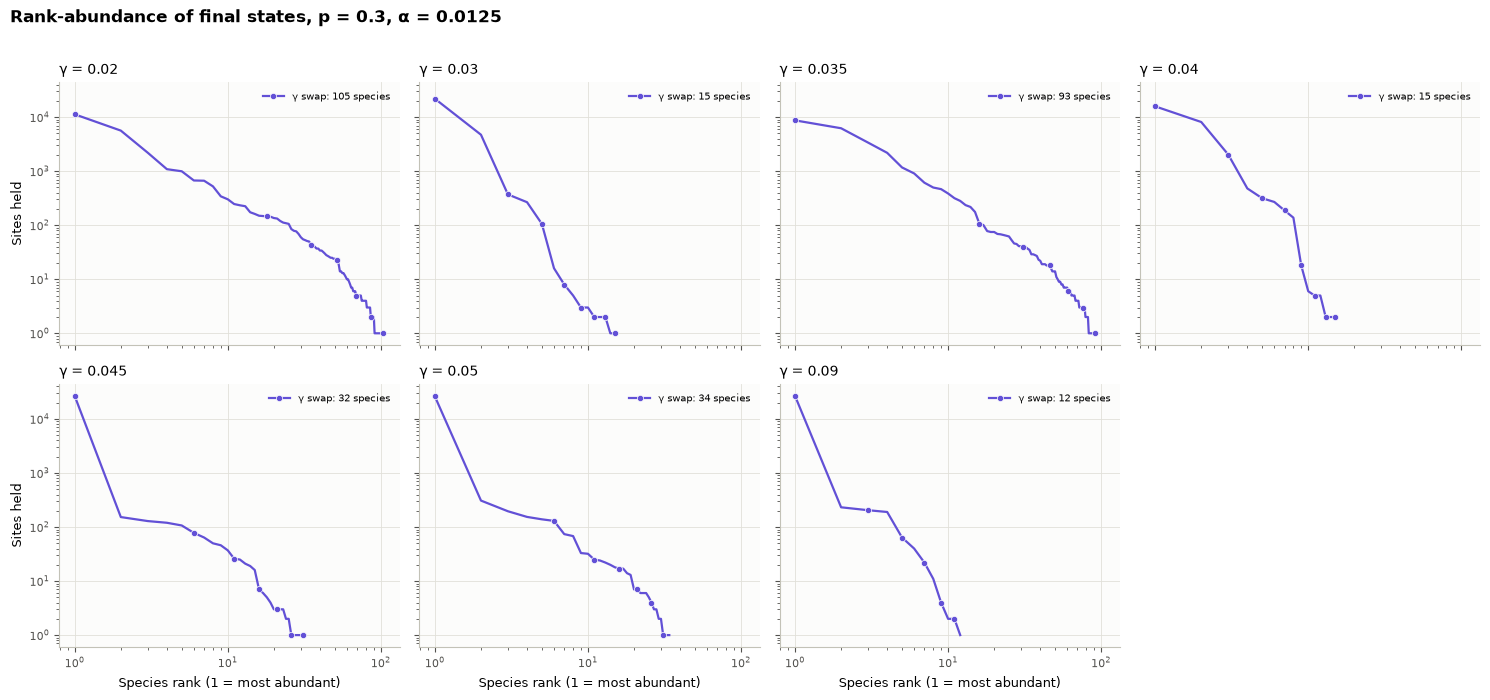

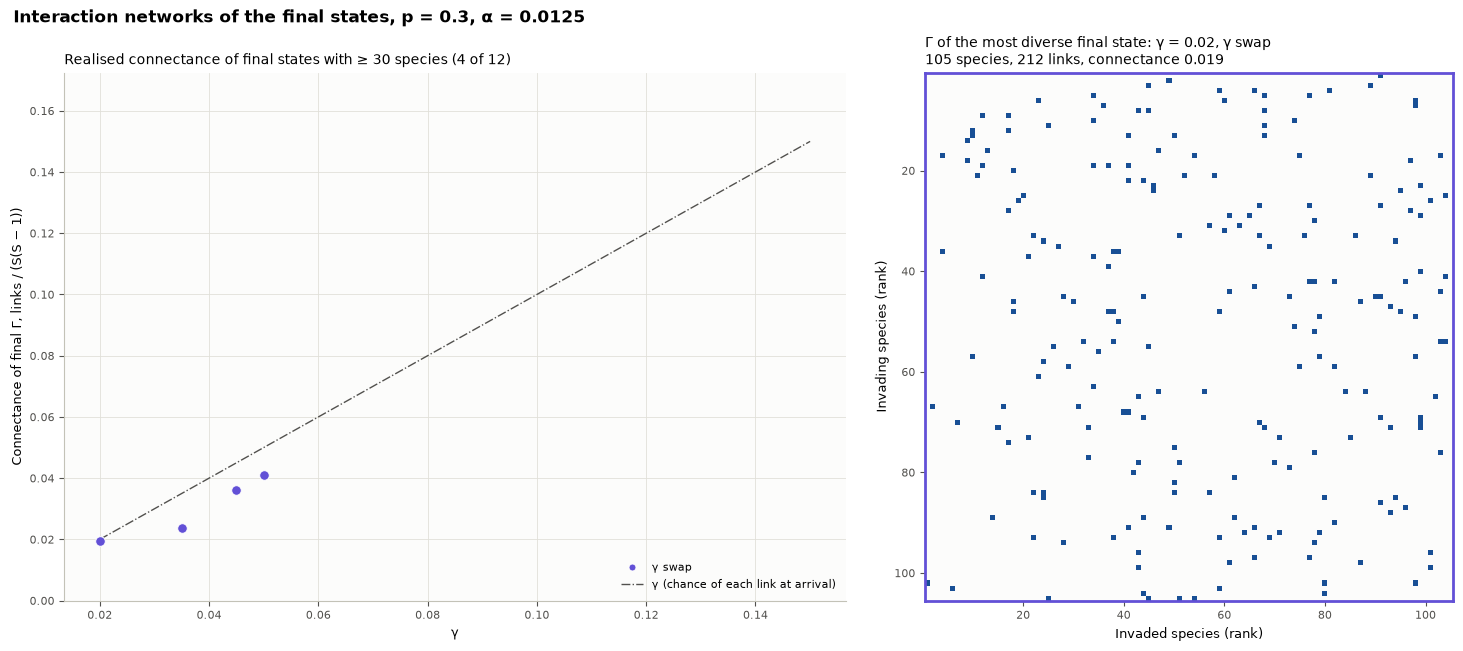

In [19]:
gamma_finals = load_final_states("gamma")
plot_final_lattices("gamma", gamma_finals, ncols=4)
gamma_structure = community_structure(gamma_finals)
plot_rank_abundance(gamma_structure)
plot_network(gamma_structure)

## 13. Inside a swap

Checkpoints are kept every 10k steps for ±1M around each swap that the simulator detected. Its detector
uses thresholds relative to each run's own level, so a stored swap can be a partial drop that this
notebook's fixed regime rule does not count. This cell shows the living-species trace across one such
window, on absolute t, with lattice snapshots at evenly spaced times. The default is branch r1 at
α = 0.007, whose first stored swap is its collapse (72 → 8 species). Choose another run with
`ZOOM_RUN = (experiment, repeat, value)` and pick among its stored swaps with `ZOOM_EVENT`.

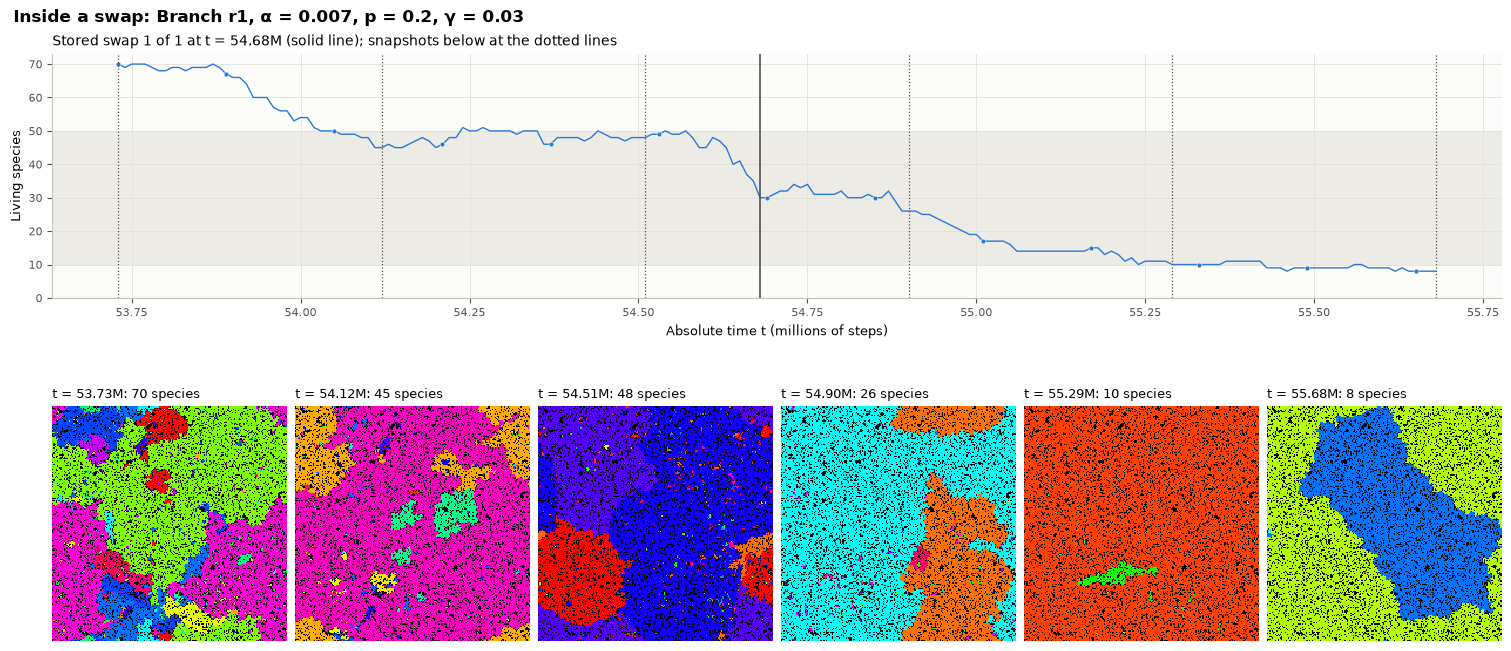

In [20]:
ZOOM_RUN = ("alpha", 1, 0.007)  # e.g. ("alpha", 2, 0.009) or ("gamma", 1, 0.07)
ZOOM_EVENT = 1  # 1 = the run's first stored swap.
SNAPSHOTS = 6

zoom = next((run for run in all_runs if run["has_checkpoints"]
             and (run["experiment"], run["repeat"]) == ZOOM_RUN[:2]
             and np.isclose(run["value"], ZOOM_RUN[2])), None)
if zoom is None or not zoom["events"].size:
    print(f"No run with checkpoints and a stored swap matches {ZOOM_RUN}.")
else:
    event = min(max(ZOOM_EVENT, 1), zoom["events"].size)
    center = int(zoom["events"][event - 1])
    paths = sorted(zoom["checkpoint_dir"].glob("checkpoint_*.npz"))
    stamps = np.array([int(path.stem.split("_")[1]) for path in paths])
    near = np.flatnonzero(np.abs(stamps - center) <= 1_200_000)
    picks = near[np.unique(np.linspace(0, near.size - 1, SNAPSHOTS).round().astype(int))]
    snapshots = [MS.load_checkpoint(paths[index]) for index in picks]
    window = (zoom["times"] >= stamps[near[0]]) & (zoom["times"] <= stamps[near[-1]])
    sym = SYMBOL[zoom["experiment"]]
    with plt.rc_context(RESULT_STYLE):
        fig = plt.figure(figsize=(15, 7.0), layout="constrained")
        grid = fig.add_gridspec(2, len(snapshots), height_ratios=[1, 1.45])
        ax_trace = fig.add_subplot(grid[0, :])
        ax_trace.axhspan(LOW, HIGH, color=BAND_COLOR, lw=0, zorder=0)
        ax_trace.plot(zoom["times"][window] / 1e6, zoom["diversity"][window], color=zoom["color"],
                      lw=1, marker=zoom["marker"], ms=3.5, mec="white", mew=0.4,
                      markevery=max(1, int(window.sum()) // 12))
        ax_trace.axvline(center / 1e6, color=PARENT_COLOR, lw=1.2)
        for state in snapshots:
            ax_trace.axvline(state["timestep"] / 1e6, color=PARENT_COLOR, ls=":", lw=0.9)
        ax_trace.set(xlabel="Absolute time t (millions of steps)", ylabel="Living species",
                     ylim=(0, None),
                     title=f"Stored swap {event} of {zoom['events'].size} at t = {center / 1e6:.2f}M "
                           f"(solid line); snapshots below at the dotted lines")
        for column, state in enumerate(snapshots):
            ax = fig.add_subplot(grid[1, column])
            ax.imshow(MS._lattice_rgba(state["lattice"]), interpolation="nearest")
            ax.set_title(f"t = {state['timestep'] / 1e6:.2f}M: {state['diversity']} species",
                         fontsize=9)
            ax.set_axis_off()
        fig.suptitle(f"Inside a swap: {zoom['name']}, {sym} = {zoom['value']:g}, "
                     f"{_experiment_title(zoom['experiment'])}", x=0.005, ha="left", fontsize=12,
                     fontweight="bold")
        plt.show()

## 14. Conclusions

These rest on the outputs above: one 100M-step window per run, fixed regime thresholds of 10 and 50
species, two sibling branches per α, and one run per γ.

**α sweep (p = 0.2, γ = 0.03).**
- **At low α a diverse community persists but does not form.** At α = 0.001 and 0.002 all four branches
  stay in the high regime through the whole second half (92-113 species on average). None of the 24
  fresh runs at α ≤ 0.007 or α = 0.009 ever reaches 50 species.
- **From α = 0.003 to 0.008 the established community usually collapses.**
  - 11 of the 12 branches fall to ≤ 10 species, 5.4M to 93.0M steps after the branch. Only r1 at
    α = 0.005 stays high throughout.
  - Branch r2 at α = 0.004 collapses at 61.6M and then re-forms (112 species at the end).
- **At α ≥ 0.009 both directions occur.**
  - 7 of 8 branches collapse at least once (first collapse 5.7-75.0M).
  - Several branches become diverse again. Branch r2 at α = 0.009 ends with 172 species. Branch r1 and
    r2 at 0.011 and r2 at 0.012 switch 2-3 times.
  - Fresh runs reach the high regime in 1 of 3 runs at α = 0.008, 0.010 and 0.011, and in 3 of 3 at
    α = 0.012 (first rises at 28.6, 31.7 and 92.7M).
- **Sibling branches from one state often disagree.**
  - At α = 0.005, r1 stays high while r2 collapses at 93.0M.
  - At α = 0.009, r1 collapses at 5.7M while r2 ends with 172 species.
  - At α = 0.010, r1 collapses at 75.0M while r2 never does.

  The fate of a community is largely down to chance within 100M steps. Differences between neighbouring
  α values in a single branch are not an α trend. The repeat 1 picture (diverse only at α = 0.001, 0.002
  and 0.005) does not replicate in repeat 2: r2 collapses at 0.005 and ends diverse at 0.004, 0.009 and
  0.010.
- Without an unchanged-α control, these runs cannot say how often parent A's state would collapse with
  no change at all. Parent A spent 22% of 25-50M outside the high regime.

**γ swap (p = 0.3, α = 0.0125).**
- **The control moves too.** With nothing changed (γ = 0.03), the branch first collapses at 19.4M,
  switches regime 9 times, and spends 51% of the second half in the high regime (mean 38 species).
  Parent B spent all of 25-50M high (mean 90).
- **γ = 0.02 is the only setting that stays diverse throughout:** no switch, mean 112, 105 species at
  the end. It lowers both the link density and the arrival rate α·γ.
- **γ = 0.035-0.05 flicker:** 6-22 regime switches, 48-90% of the second half in the high regime.
- **γ ≥ 0.055 does not hold a diverse state:** at most 7% of the second half is high. From γ = 0.07 on,
  the collapse comes within 0.5-0.8M steps of the swap and is never reversed. The collapsed state keeps
  more species (means 8-20) than the collapsed runs of the α sweep (about 1-8), with introductions
  1.8-5 × more frequent than in the parent.
- **At γ ≥ 0.05 the starting state is forgotten.** The branches' second-half means (29.7, 16.2 and 12.0
  at γ = 0.05, 0.07 and 0.09) match those of the grid runs that started from one species (25.2, 15.0 and
  12.5).

**Both experiments.**
- No species alive at the branch point survives to t = 150M in any branch. Every final community was
  assembled after the parameter change.
- The number of species introduced in each branch matches α·γ·T within counting noise. The largest of
  the 36 deviations is 2.0 √(α·γ·T) (branch r2 at α = 0.005: 15,245 against 15,000), which is ordinary
  for 36 Poisson counts (tables in sections 9 and 12).
- Every final community with ≥ 30 species has a connectance below γ: 0.017-0.023 at γ = 0.03, 0.019 at
  γ = 0.02, and 0.024-0.041 at γ = 0.035-0.05.